# ICT4403 Foundations of Generative AI: Assignment 3
## English to Hindi Machine Translation with a Basic Transformer, mT5, LLaMA and Gemma

This notebook implements the approved `PLAN.md` and `IMPLEMENTATION_BLUEPRINT.md` in one runnable Kaggle notebook. It trains or adapts four systems on one parallel corpus, translates the **same held-out test sentences** with all of them, and reports BLEU, chrF, training time, inference time and parameter counts, followed by temperature, qualitative and responsible-AI analysis.

**What is verified and what is not.** Nothing in this notebook is a result until you run it. Every number reported later is computed from actual model outputs and saved under `/kaggle/working/assignment3_outputs/`. If a model cannot run (access, memory, network), the notebook records the failure and continues; it never substitutes another model or invents a score.

### Run order
1. Settings, Add-ons: *Accelerator = GPU*. Internet **On** if you download from Hugging Face; **Off** if you attach the data and models as Kaggle inputs (see `KAGGLE_EXECUTION_GUIDE.md`).
2. Choose `PROFILE` in section 2 (`smoke`, `session`, `plan_full`) and run all cells top to bottom.
3. Download `/kaggle/working/assignment3_outputs.zip`.

### Decisions that differ from the plan (all configurable in section 2)
| Topic | Plan / blueprint | This notebook | Why |
|---|---|---|---|
| Notebook count | six notebooks | **one notebook**, one function `run_system` per model, resumable | requested deliverable |
| Training subset | 100,000 pairs | profile `session`: 20,000 pairs (profile `plan_full` restores 100,000) | one Kaggle session |
| Validation / test | official 520 / 2,507 | `session`: all official validation pairs (at most 1,000) and a seeded random 500 test pairs, identical for all four models | one Kaggle session |
| SentencePiece vocabulary | 16,000 | `session`: 8,000 (profile `plan_full`: 16,000) | fewer training pairs |
| Held-out in-domain set | optional | skipped | optional in the plan |
| Model IDs | Llama 3.2 1B base, Gemma 3 1B pt | same by default; `MODEL_PRESET="user_preferred"` switches to Llama 3.2 1B Instruct and Gemma 2 2B it (chat templates are handled) | comparable ~1B sizes; both options supported |

## Final run configuration — Gemma numerical-stability fix

- Transformer, mT5, Llama 3.2 1B, and Gemma 3 1B are enabled.
- The latest run completed Transformer, mT5, and Llama successfully. Gemma downloaded and loaded, but its first loss check returned NaN for both the shared loss and Hugging Face loss.
- This is consistent with numerical instability in the FP16 execution path, not a gated-repository or token problem.
- **Gemma is now configured for FP32**, with micro-batch 1, gradient accumulation 32, sequence length 192, and gradient checkpointing to reduce memory use. Llama remains in FP16.
- `RESUME=True` reuses the three completed models if their result files remain in `/kaggle/working/assignment3_outputs`; Gemma will be retried.
- Keep the Kaggle `HF_TOKEN` secret enabled. Run all cells from the beginning in the same Kaggle working session if possible.

In [1]:
# ===================== 1. ENVIRONMENT, DEPENDENCIES, HARDWARE =====================
import os, sys, subprocess, importlib, importlib.util
# Transformers detects torchao when it is installed. Kaggle's preinstalled
# torchao 0.10.0 is incompatible with this Transformers build (it requires >0.16).
# This notebook does not use torchao/quantization, so remove the stale optional
# package before importing Transformers. This avoids the Llama/Gemma import crash.
_ta_uninstall = subprocess.run(
    [sys.executable, "-m", "pip", "uninstall", "-y", "torchao"],
    capture_output=True, text=True
)
if _ta_uninstall.returncode == 0 and ("Successfully uninstalled" in _ta_uninstall.stdout or "not installed" in (_ta_uninstall.stdout + _ta_uninstall.stderr).lower()):
    print("[setup] incompatible optional torchao removed (or not present)")
importlib.invalidate_caches()

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")     # one GPU: identical conditions and timing for every model
LOCAL_TEST = os.environ.get("A3_LOCAL_TEST") == "1"     # developer-only validation hook (section 4); leave unset on Kaggle

def _ensure(import_name, pip_name):
    if importlib.util.find_spec(import_name) is None:
        print(f"[setup] installing {pip_name} ...")
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], capture_output=True, text=True)
        if r.returncode != 0:
            print(f"[setup] pip install {pip_name} FAILED (Internet off?). Enable Internet or attach an offline wheel dataset.\n", r.stderr[-300:])
for _imp, _pip in [("sacrebleu", "sacrebleu"), ("sentencepiece", "sentencepiece"), ("peft", "peft"),
                   ("datasets", "datasets"), ("pyarrow", "pyarrow")]:
    _ensure(_imp, _pip)

import json, time, math, random, re, gc, hashlib, shutil, unicodedata, platform, warnings, zipfile, traceback, copy, itertools
from dataclasses import dataclass, field, asdict
from pathlib import Path
from types import SimpleNamespace
from typing import Any, Dict, List, Optional, Tuple
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers, sacrebleu, sentencepiece as spm
try:
    import peft
except Exception as _e:
    peft = None; print("[setup] peft unavailable:", _e)
warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
ENV = {
    "python": sys.version.split()[0], "platform": platform.platform(), "torch": torch.__version__,
    "transformers": transformers.__version__, "peft": getattr(peft, "__version__", None),
    "sacrebleu": sacrebleu.__version__, "sentencepiece": spm.__version__, "pandas": pd.__version__, "numpy": np.__version__,
    "cuda_available": torch.cuda.is_available(), "cuda_version": torch.version.cuda, "gpu_count": torch.cuda.device_count(),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "gpu_mem_gb": round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if torch.cuda.is_available() else None,
    "bf16_supported": bool(torch.cuda.is_available() and torch.cuda.is_bf16_supported()),
    "bitsandbytes": importlib.util.find_spec("bitsandbytes") is not None,
}
for k, v in ENV.items(): print(f"{k:>16}: {v}")
if not torch.cuda.is_available():
    print("\n[warning] CUDA is not available. Only the 'smoke' profile is realistic on CPU.")
if ENV["gpu_count"] > 1:
    print("[warning] more than one GPU visible; this notebook uses cuda:0 only (single-GPU timing).")

[setup] incompatible optional torchao removed (or not present)
[setup] installing sacrebleu ...
          python: 3.13.15
        platform: Linux-6.18.55+-x86_64-with-glibc2.39
           torch: 2.11.0+cu128
    transformers: 5.16.1
            peft: 0.20.0
       sacrebleu: 2.6.0
   sentencepiece: 0.2.2
          pandas: 2.3.3
           numpy: 2.1.3
  cuda_available: True
    cuda_version: 12.8
       gpu_count: 1
        gpu_name: Tesla T4
      gpu_mem_gb: 15.6
  bf16_supported: True
    bitsandbytes: False


In [2]:
# ===================== 2. CENTRAL CONFIGURATION =====================
# Pick the profile. 'smoke': minutes, tiny budgets (pipeline check).  'session': one Kaggle GPU session.
# 'plan_full': the approved plan's budgets (several GPU hours, run model by model, see RUN_MODELS and RESUME).
PROFILE = os.environ.get("A3_PROFILE", "session")                 # "smoke" | "session" | "plan_full"
MODEL_PRESET = os.environ.get("A3_MODEL_PRESET", "plan")          # "plan" | "user_preferred"
RUN_MODELS = {"transformer": True, "mt5": True, "llama": True, "gemma": True}   # switch models off to run them in separate sessions
RESUME = True                                                       # skip a model whose results already exist in OUT
DATASET = os.environ.get("A3_DATASET", "iitb")                    # "iitb" (approved plan) | "samanantar" (alternative, section 5)

MODEL_PRESETS = {
    "plan":           {"mt5": "google/mt5-small", "llama": "meta-llama/Llama-3.2-1B",          "gemma": "google/gemma-3-1b-pt"},
    "user_preferred": {"mt5": "google/mt5-small", "llama": "meta-llama/Llama-3.2-1B-Instruct", "gemma": "google/gemma-2-2b-it"},
}
MODEL_IDS = dict(MODEL_PRESETS[MODEL_PRESET])
MODEL_PATH_OVERRIDE: Dict[str, str] = {}      # e.g. {"llama": "/kaggle/input/llama-3.2/transformers/1b/1"} to force an attached model
USE_4BIT = {"llama": False, "gemma": MODEL_PRESET == "user_preferred"}   # QLoRA for the 2.6B Gemma 2 preset (needs bitsandbytes + GPU)

OUT = Path(os.environ.get("A3_OUT", "/kaggle/working/assignment3_outputs"))
for _d in ["config", "results", "translations", "plots", "checkpoints", "logs"]:
    (OUT / _d).mkdir(parents=True, exist_ok=True)

@dataclass
class TrainCfg:
    name: str
    precision: str = "fp32"          # "fp32" | "fp16_amp"
    micro_batch: int = 16
    accum: int = 1
    epochs: int = 1
    lr: float = 1e-4
    schedule: str = "linear"         # "inv_sqrt" | "linear" | "cosine"
    warmup: float = 0.03             # steps if >= 1, fraction of total steps if < 1
    weight_decay: float = 0.0
    betas: tuple = (0.9, 0.999)
    eps: float = 1e-8
    clip: float = 1.0
    label_smoothing: float = 0.0
    eval_every: Any = "epoch"        # "epoch" or an int number of optimizer steps
    patience: Optional[int] = None
    max_len: int = 192
    max_steps: Optional[int] = None  # hard cap on optimizer steps (smoke tests)

BASE = dict(
    seed=42, candidate_factor=8,
    filters=dict(en_words=(3, 50), hi_words=(3, 60), ratio_max=3.0, script_min=0.5),
    word_bins=(10, 25), infer_batch=32, latency_n=20, max_src_tokens_test=256,
    mnt_rule=dict(floor=128, cap=512, mult=2.0, pct=99),
    temps=(0.5, 1.0, 1.5), sample_seed_base=1000, instruction="Translate the following English sentence into Hindi.",
    hf_iitb="cfilt/iitb-english-hindi", hf_samanantar="nirmalendu01/samanantar-parallel-en-hi-bn-ta-te",
    lora=dict(r=16, alpha=32, dropout=0.05, targets=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]),
    fewshot_k=5, run_fewshot=False, grad_ckpt=False,
)
PROFILES = {
  "smoke": dict(max_train=300, max_valid=60, max_test=40, analysis_per_bin=10, audit_per_bin=3, temp_n_samples=2, temp_max_sent=24,
      bootstrap_n=40, latency_n=4, spm_vocab=300, run_fewshot=True,
      arch=dict(d_model=64, heads=4, layers=2, ff=128, dropout=0.1),
      tcfg={"transformer": TrainCfg("transformer", "fp32", 32, 1, 6, 1e-3, "inv_sqrt", 30, 0.01, (0.9, 0.98), 1e-9, 1.0, 0.1, "epoch", 3, 128),
            "mt5":   TrainCfg("mt5", "fp32", 16, 1, 1, 3e-4, "linear", 0.1, 0.01, max_len=64, max_steps=8),
            "llama": TrainCfg("llama", "fp32", 8, 2, 1, 2e-4, "cosine", 2, 0.0, eval_every=4, max_len=128, max_steps=8),
            "gemma": TrainCfg("gemma", "fp32", 8, 2, 1, 2e-4, "cosine", 2, 0.0, eval_every=4, max_len=128, max_steps=8)}),
  "session": dict(max_train=20000, max_valid=1000, max_test=500, analysis_per_bin=34, audit_per_bin=10, temp_n_samples=2, temp_max_sent=100,
      bootstrap_n=300, latency_n=20, spm_vocab=8000, run_fewshot=True,
      arch=dict(d_model=512, heads=8, layers=4, ff=2048, dropout=0.3),
      tcfg={"transformer": TrainCfg("transformer", "fp16_amp", 64, 1, 30, 5e-4, "inv_sqrt", 800, 0.01, (0.9, 0.98), 1e-9, 1.0, 0.1, "epoch", 4, 256),
            "mt5":   TrainCfg("mt5", "fp32", 32, 1, 3, 3e-4, "linear", 0.03, 0.01, max_len=192),
            "llama": TrainCfg("llama", "fp16_amp", 16, 2, 1, 2e-4, "cosine", 100, 0.0, eval_every=250, max_len=384),
            "gemma": TrainCfg("gemma", "fp16_amp", 8, 4, 1, 2e-4, "cosine", 100, 0.0, eval_every=250, max_len=384)}),
  "plan_full": dict(max_train=100000, max_valid=None, max_test=None, analysis_per_bin=100, audit_per_bin=10, temp_n_samples=3, temp_max_sent=300,
      bootstrap_n=1000, latency_n=20, spm_vocab=16000, run_fewshot=True,
      arch=dict(d_model=512, heads=8, layers=4, ff=2048, dropout=0.3),
      tcfg={"transformer": TrainCfg("transformer", "fp16_amp", 64, 1, 25, 5e-4, "inv_sqrt", 2000, 0.01, (0.9, 0.98), 1e-9, 1.0, 0.1, "epoch", 3, 256),
            "mt5":   TrainCfg("mt5", "fp32", 32, 1, 3, 3e-4, "linear", 0.03, 0.01, max_len=192),
            "llama": TrainCfg("llama", "fp16_amp", 16, 2, 1, 2e-4, "cosine", 100, 0.0, eval_every=500, max_len=384),
            "gemma": TrainCfg("gemma", "fp16_amp", 8, 4, 1, 2e-4, "cosine", 100, 0.0, eval_every=500, max_len=384)}),
}
CFG = SimpleNamespace(**{**BASE, **PROFILES[PROFILE]})
# Deadline-safe overrides: preserve the same 500 test examples but reduce GPU memory/time.
CFG.infer_batch = 4
CFG.latency_n = 5
CFG.temp_max_sent = 24
CFG.temp_n_samples = 1
CFG.run_fewshot = False
CFG.tcfg["mt5"].micro_batch = 1
CFG.tcfg["mt5"].accum = 8
CFG.tcfg["mt5"].epochs = 1
CFG.tcfg["mt5"].max_len = 128
CFG.tcfg["mt5"].max_steps = 1000
CFG.tcfg["mt5"].precision = "fp32"  # mT5 fp16 was intentionally avoided for stability

CFG.profile, CFG.dataset, CFG.model_ids, CFG.model_preset = PROFILE, DATASET, MODEL_IDS, MODEL_PRESET
if PROFILE == "smoke" and not LOCAL_TEST:
    print("[note] 'smoke' profile on Kaggle still downloads the real models; use it to test access, not for results.")
print(f"profile={PROFILE}  dataset={DATASET}  preset={MODEL_PRESET}\nmodels={MODEL_IDS}")
print({k: getattr(CFG, k) for k in ["max_train", "max_valid", "max_test", "temp_n_samples", "temp_max_sent", "bootstrap_n", "spm_vocab"]})
# LLaMA access is available; RUN_MODELS['llama'] is enabled for this final run.

# Deadline-safe overrides for a Kaggle T4.
CFG.infer_batch = 4
CFG.latency_n = 5
CFG.temp_max_sent = 24
CFG.temp_n_samples = 1
CFG.run_fewshot = False
CFG.tcfg["mt5"].micro_batch = 1
CFG.tcfg["mt5"].accum = 8
CFG.tcfg["mt5"].epochs = 1
CFG.tcfg["mt5"].max_len = 128
CFG.tcfg["mt5"].max_steps = 1000
CFG.tcfg["mt5"].precision = "fp32"


# FINAL DEADLINE OVERRIDES
# Llama implementation is retained and enabled for this final run.
# Gemma implementation is retained and enabled; ensure your Kaggle HF token has access.
CFG.infer_batch = 4
CFG.latency_n = 5
CFG.temp_max_sent = 24
CFG.temp_n_samples = 1
CFG.run_fewshot = False
CFG.tcfg["mt5"].micro_batch = 1
CFG.tcfg["mt5"].accum = 8
CFG.tcfg["mt5"].epochs = 1
CFG.tcfg["mt5"].max_len = 128
CFG.tcfg["mt5"].max_steps = 1000
CFG.tcfg["mt5"].precision = "fp32"


# Decoder-only LoRA memory settings for a Kaggle T4 (Llama 3.2 1B / Gemma 3 1B).
# Keep effective batch size near the original session setting while lowering
# per-step activation memory. Gradient checkpointing trades speed for memory.
CFG.grad_ckpt = True
for _model_name in ("llama", "gemma"):
    CFG.tcfg[_model_name].micro_batch = 1
    CFG.tcfg[_model_name].accum = 32
    CFG.tcfg[_model_name].max_len = 256
    CFG.tcfg[_model_name].precision = "fp16_amp"

# Gemma 3 1B produced NaN logits/loss in fp16 on the Tesla T4 during the
# initial loss-equivalence test. Run Gemma in full FP32 (no autocast) for
# numerical stability; micro-batch 1 + gradient checkpointing limit memory.
CFG.tcfg["gemma"].precision = "fp32"
CFG.tcfg["gemma"].max_len = 192
CFG.tcfg["gemma"].micro_batch = 1
CFG.tcfg["gemma"].accum = 32


profile=session  dataset=iitb  preset=plan
models={'mt5': 'google/mt5-small', 'llama': 'meta-llama/Llama-3.2-1B', 'gemma': 'google/gemma-3-1b-pt'}
{'max_train': 20000, 'max_valid': 1000, 'max_test': 500, 'temp_n_samples': 1, 'temp_max_sent': 24, 'bootstrap_n': 300, 'spm_vocab': 8000}


In [3]:
# ===================== 3. UTILITIES: seeds, timing, files, memory =====================
def seed_everything(seed: int) -> None:
    """Seed python, numpy, torch (CPU and CUDA) and transformers. GPU kernels may still be non-deterministic."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    transformers.set_seed(seed)
    torch.backends.cudnn.benchmark = False

def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

class Timer:
    def __enter__(self): sync(); self.t0 = time.perf_counter(); return self
    def __exit__(self, *a): sync(); self.seconds = time.perf_counter() - self.t0

def sha256_file(p) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()

def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f: json.dump(obj, f, ensure_ascii=False, indent=2, default=str)

def write_jsonl(recs, path):
    with open(path, "w", encoding="utf-8") as f:
        for r in recs: f.write(json.dumps(r, ensure_ascii=False) + "\n")

def dir_size_mb(p) -> Optional[float]:
    p = Path(p)
    if not p.exists(): return None
    if p.is_file(): return round(p.stat().st_size / 1e6, 2)
    return round(sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6, 2)

def cleanup():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache(); torch.cuda.ipc_collect()

def gpu_mem_gb() -> Optional[float]:
    return round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else None

def get_hf_token() -> Optional[str]:
    """Token from env HF_TOKEN or Kaggle Secrets (secret name HF_TOKEN). Never printed or saved."""
    tok = os.environ.get("HF_TOKEN") or os.environ.get("HUGGING_FACE_HUB_TOKEN")
    if tok: return tok
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        return None
HF_TOKEN = get_hf_token()
print("HF token available:", HF_TOKEN is not None, "(value hidden)")
HF_HOME = "/kaggle/temp/hf_cache" if Path("/kaggle/temp").exists() else str(Path.home() / ".cache" / "huggingface")
os.environ.setdefault("HF_HOME", HF_HOME)

def internet_available(host="huggingface.co", timeout=4) -> bool:
    import socket
    try:
        socket.create_connection((host, 443), timeout=timeout).close(); return True
    except Exception:
        return False
INTERNET = internet_available() or os.environ.get("A3_FORCE_INTERNET") == "1"
print("Internet reachable:", INTERNET)

def count_params_meta(path_or_id: str, kind: str) -> Optional[int]:
    """Parameter count from the config alone (meta device), before loading any weights."""
    try:
        from transformers import AutoConfig, AutoModelForCausalLM, AutoModelForSeq2SeqLM
        cfgm = AutoConfig.from_pretrained(path_or_id, token=HF_TOKEN)
        cls = AutoModelForSeq2SeqLM if kind == "seq2seq" else AutoModelForCausalLM
        with torch.device("meta"):
            m = cls.from_config(cfgm)
        return int(sum(p.numel() for p in m.parameters()))
    except Exception as e:
        print(f"[memory] could not count parameters for {path_or_id}: {type(e).__name__}: {str(e)[:120]}")
        return None

def estimate_and_warn(name: str, n_params: Optional[int], weight_bytes: float, trainable_frac: float, full_ft: bool) -> Dict:
    """Rough GPU memory estimate: weights + gradients and Adam states for the trainable part + 25% overhead (activations excluded)."""
    if n_params is None: return {"model": name, "estimate_gb": None}
    w = n_params * weight_bytes
    tr = n_params * trainable_frac
    grads_opt = tr * (4 + 8)
    est = (w + grads_opt) * 1.25 / 1e9
    info = {"model": name, "n_params": n_params, "estimate_gb": round(est, 2), "gpu_gb": ENV["gpu_mem_gb"]}
    print(f"[memory] {name}: ~{est:.1f} GB before activations (params {n_params/1e6:.0f}M)")
    if ENV["gpu_mem_gb"] and est > 0.85 * ENV["gpu_mem_gb"]:
        print(f"[warning] {name}: estimate exceeds 85% of GPU memory ({ENV['gpu_mem_gb']} GB). Use 4-bit, a smaller micro-batch or a smaller model.")
    return info

HF token available: True (value hidden)
Internet reachable: True


In [4]:
# ===================== TEXT UTILITIES (Hindi-safe) =====================
def nfc(s: str) -> str: return unicodedata.normalize("NFC", s)
def collapse_ws(s: str) -> str: return " ".join(s.split())
def key_exact(s: str) -> str: return collapse_ws(nfc(s)).lower()
def key_loose(s: str) -> str:
    """Comparison key: drop punctuation, symbols, digits and control/format characters; KEEP letters and combining marks
    (Devanagari vowel signs are combining marks and must not be stripped)."""
    s = key_exact(s)
    return collapse_ws("".join(ch for ch in s if unicodedata.category(ch)[0] in "LMZ"))

_DEVA = re.compile(r"[\u0900-\u0963\u0970-\u097F]")     # letters and vowel signs; excludes danda (0964/0965) and digits (0966-096F)
_LATN = re.compile(r"[A-Za-z]")
def script_share(s: str, which: str = "deva") -> float:
    d, l = len(_DEVA.findall(s)), len(_LATN.findall(s))
    if d + l == 0: return 0.0
    return (d if which == "deva" else l) / (d + l)

def n_words(s: str) -> int: return len(s.split())
def has_url(s: str) -> bool: return re.search(r"https?://|www\.", s) is not None

_PUNCT = r'([।॥,.;:!?"\'“”‘’()\[\]{}<>/\\|@#$%^&*+=~`_\-–—…])'
def hi_tok(s: str) -> str:
    """Offline-safe tokenization for BLEU on Hindi: NFC, separate punctuation (including the danda), collapse spaces."""
    s = re.sub(_PUNCT, r" \1 ", nfc(s))
    return " ".join(s.split())

_DEVA_DIGITS = str.maketrans("०१२३४५६७८९", "0123456789")
def numbers_in(s: str) -> List[str]:
    s = s.translate(_DEVA_DIGITS)
    return re.findall(r"\d+(?:[.,:]\d+)*", s)
def norm_num(x: str) -> str: return x.replace(",", "")

# ---- unit checks (fail loudly if the Hindi-safe helpers are wrong) ----
assert key_loose("Hello, World 2!") == "hello world"
assert script_share("हिंदी वाक्य", "deva") == 1.0 and script_share("की", "deva") == 1.0 and script_share("English", "deva") == 0.0
assert hi_tok("यह है।") == "यह है ।"
assert [norm_num(x) for x in numbers_in("कीमत ५,००,००० रुपये")] == ["500000"]
print("text utilities OK")

text utilities OK


## 4. Developer validation hook (ignored on Kaggle)
When the environment variable `A3_LOCAL_TEST=1` is set, this cell builds a **synthetic** English to Hindi toy corpus and **tiny random models** so the whole notebook can be exercised on a CPU without downloads. It does nothing on Kaggle. The scores produced in that mode are meaningless; it only checks data flow, shapes, masking, loss, generation, export and error handling.

In [5]:
# ===================== 4. DEVELOPER VALIDATION HOOK (only when A3_LOCAL_TEST=1) =====================
if LOCAL_TEST:
    from tokenizers import Tokenizer, models as tkm, trainers as tkt, pre_tokenizers as tkp, decoders as tkd, processors as tkproc
    from transformers import PreTrainedTokenizerFast, MT5Config, MT5ForConditionalGeneration, LlamaConfig, LlamaForCausalLM
    _root = Path(os.environ.get("A3_LOCAL_ROOT", "/tmp/a3_local")); shutil.rmtree(_root, ignore_errors=True); (_root / "raw").mkdir(parents=True)
    _EN = "ram sita house water book school child boy girl city village road tree flower river mountain sky sun moon star".split()
    _HI = "राम सीता घर पानी किताब स्कूल बच्चा लड़का लड़की शहर गाँव सड़क पेड़ फूल नदी पहाड़ आसमान सूरज चाँद तारा".split()
    _rng = random.Random(7)
    def _pair():
        k = _rng.randint(3, 7); idx = [_rng.randrange(20) for _ in range(k)]
        en = " and ".join(_EN[i] for i in idx); hi = " और ".join(_HI[i] for i in idx)
        if _rng.random() < 0.3:
            n = _rng.randint(2, 99); en, hi = f"{n} {en}", f"{n} {hi}"
        return en.capitalize() + ".", hi + "।"
    def _uniq(n, banned=()):
        seen, out = set(banned), []
        while len(out) < n:
            p = _pair()
            if p[0] not in seen: seen.add(p[0]); out.append(p)
        return out
    _test = _uniq(100); _valid = _uniq(100, [p[0] for p in _test]); _train = _uniq(3000, [p[0] for p in _test + _valid])
    _train += [("", "खाली"), ("Only one", "एक"), ("Bad latin pair here now", "this is not hindi at all"), (_train[0][0], _train[0][1]), (_train[1][0], _train[1][1])]
    _train += [(_test[0][0], "गलत अनुवाद लीक"), (_test[1][0].lower(), _test[1][1])]            # leakage cases that must be removed
    for name, pairs in [("train", _train), ("validation", _valid), ("test", _test)]:
        pd.DataFrame({"translation": [{"en": e, "hi": h} for e, h in pairs]}).to_parquet(_root / "raw" / f"{name}.parquet")
    os.environ["A3_RAW_DIR"] = str(_root / "raw")
    (_root / "samanantar").mkdir(); _all = _train + _valid + _test
    pd.DataFrame({"en": [e for e, _ in _all], "hi": [h for _, h in _all], "bn": "x"}).to_parquet(_root / "samanantar" / "samanantar_part.parquet"); os.environ["A3_SAMANANTAR_DIR"] = str(_root / "samanantar")
    _corpus = [e for e, _ in _train + _valid + _test] + [h for _, h in _train + _valid + _test] + ["Translate the following English sentence into Hindi.", "English:", "Hindi:", "translate English to Hindi:"]
    def _tiny_tok(specials, post):
        tk = Tokenizer(tkm.BPE(unk_token="<unk>")); tk.pre_tokenizer = tkp.Metaspace(); tk.decoder = tkd.Metaspace()
        tk.train_from_iterator(_corpus, tkt.BpeTrainer(vocab_size=500, special_tokens=specials))
        tk.post_processor = tkproc.TemplateProcessing(single=post, special_tokens=[(s, tk.token_to_id(s)) for s in specials if s in post])
        return tk
    _chat = ("{{ bos_token }}{% for m in messages %}<start_of_turn>{{ m['role'] }}\n{{ m['content'] }}<end_of_turn>\n{% endfor %}"
             "{% if add_generation_prompt %}<start_of_turn>model\n{% endif %}")
    _tk = _tiny_tok(["<pad>", "</s>", "<unk>"], "$A </s>")
    _t5 = PreTrainedTokenizerFast(tokenizer_object=_tk, pad_token="<pad>", eos_token="</s>", unk_token="<unk>"); _t5.save_pretrained(_root / "mt5")
    MT5ForConditionalGeneration(MT5Config(vocab_size=_tk.get_vocab_size(), d_model=32, d_kv=8, d_ff=64, num_layers=2, num_decoder_layers=2, num_heads=4,
        pad_token_id=0, eos_token_id=1, decoder_start_token_id=0)).save_pretrained(_root / "mt5")
    for _name, _extra, _tmpl in [("llama", [], None), ("gemma", ["<start_of_turn>", "<end_of_turn>"], _chat)]:
        _tk2 = _tiny_tok(["<unk>", "<s>", "</s>"] + _extra, "<s> $A")
        _tok = PreTrainedTokenizerFast(tokenizer_object=_tk2, unk_token="<unk>", bos_token="<s>", eos_token="</s>")
        if _tmpl: _tok.chat_template = _tmpl
        _tok.save_pretrained(_root / _name)
        LlamaForCausalLM(LlamaConfig(vocab_size=_tk2.get_vocab_size(), hidden_size=32, intermediate_size=64, num_hidden_layers=2,
            num_attention_heads=4, num_key_value_heads=4, max_position_embeddings=512, bos_token_id=1, eos_token_id=2)).save_pretrained(_root / _name)
    MODEL_PATH_OVERRIDE.update({k: str(_root / k) for k in ["mt5", "llama", "gemma"]})
    MODEL_IDS.update({"mt5": "local/tiny-mt5", "llama": "local/tiny-llama", "gemma": "local/tiny-gemma-it"}); CFG.model_ids = MODEL_IDS
    USE_4BIT.update({"llama": False, "gemma": False}); INTERNET = False
    print("[local test] synthetic corpus and tiny models ready in", _root)
else:
    print("local validation hook inactive (normal Kaggle run)")

local validation hook inactive (normal Kaggle run)


## 5. Dataset: location, inspection and licence

**Default dataset (approved plan): IIT Bombay English-Hindi Parallel Corpus (IITB)**, English as source and Hindi as target.
* Source: https://huggingface.co/datasets/cfilt/iitb-english-hindi (official corpus page named in the paper: http://www.cfilt.iitb.ac.in/iitb_parallel).
* Official splits: train, validation, test. The corpus paper states that dev and test are the WMT 2014 English-Hindi newswire sets, while the training data is a mixture (software strings, Quran text, government text, dictionary entries and others).
* Licence: the Hugging Face card shows **CC BY-NC 4.0**; the paper says newly released parts are CC BY-NC-SA 4.0 and compiled parts keep their own licences. Treat it as **non-commercial research use only**, do not redistribute the data.
* Citation: Kunchukuttan, Mehta, Bhattacharyya. *The IIT Bombay English-Hindi Parallel Corpus.* LREC 2018.

**Alternative (`DATASET="samanantar"`)**: https://huggingface.co/datasets/nirmalendu01/samanantar-parallel-en-hi-bn-ta-te, derived from https://huggingface.co/datasets/ai4bharat/samanantar. The dataset card lists columns `en, hi, bn, ta, te`, a single `train` split of 379,437 rows and licence **cc-by-nc-4.0** (provenance: Samanantar v0.3.0). Rows in the card preview include **visibly misaligned pairs**, so noise is expected. It has no validation/test split, so this notebook creates a deterministic hash-based split on the English side (no source sentence can appear in two splits).

The notebook never trusts these notes for numbers: it prints the real schema, counts, nulls, duplicates and length statistics before using anything.

In [6]:
# ===================== 5. LOCATE, LOAD AND INSPECT THE DATASET =====================
print("Contents of /kaggle/input:")
if Path("/kaggle/input").exists():
    for p in sorted(Path("/kaggle/input").iterdir())[:30]: print("  ", p)
else:
    print("   (not on Kaggle)")

DATASET_INFO = {
    "iitb": dict(name="IIT Bombay English-Hindi Parallel Corpus", url="https://huggingface.co/datasets/cfilt/iitb-english-hindi",
                 original="http://www.cfilt.iitb.ac.in/iitb_parallel", license="CC BY-NC 4.0 (HF card); paper: CC BY-NC-SA 4.0 for new parts, upstream licences otherwise. Non-commercial research use only.",
                 citation="Kunchukuttan, Mehta, Bhattacharyya. The IIT Bombay English-Hindi Parallel Corpus. LREC 2018."),
    "samanantar": dict(name="Samanantar EN-HI (derived, nirmalendu01)", url="https://huggingface.co/datasets/nirmalendu01/samanantar-parallel-en-hi-bn-ta-te",
                 original="https://huggingface.co/datasets/ai4bharat/samanantar", license="cc-by-nc-4.0 (HF card); source Samanantar v0.3.0 CC BY-NC 4.0 per the card provenance.",
                 citation="Ramesh et al. Samanantar: The Largest Publicly Available Parallel Corpora Collection for 11 Indic Languages. TACL 2022."),
}[DATASET]

def _flatten(df: pd.DataFrame) -> pd.DataFrame:
    if "translation" in df.columns:
        tr = df["translation"]
        return pd.DataFrame({"en": [d["en"] for d in tr], "hi": [d["hi"] for d in tr]}, index=df.index)
    if {"en", "hi"} <= set(df.columns): return df[["en", "hi"]].copy()
    raise ValueError(f"Unexpected schema: columns={list(df.columns)}. Expected 'translation' (en, hi) or columns 'en' and 'hi'.")

def _find_iitb_files():
    roots = [os.environ["A3_RAW_DIR"]] if os.environ.get("A3_RAW_DIR") else ([str(p) for p in Path("/kaggle/input").iterdir()] if Path("/kaggle/input").exists() else [])
    for r in roots:
        files = list(Path(r).rglob("*.parquet"))
        pick = lambda kw: [p for p in files if kw in p.name.lower()]
        tr, va, te = pick("train"), (pick("valid") or pick("val")), pick("test")
        if tr and va and te: return tr[0], va[0], te[0]
    return None

def _sample_idx(n, k, rng): return sorted(rng.sample(range(n), k)) if k < n else list(range(n))

def load_raw() -> Tuple[Dict[str, pd.DataFrame], Dict]:
    rng = random.Random(CFG.seed); info = {"dataset": DATASET, **DATASET_INFO}
    cand = lambda n: min(n, max(CFG.candidate_factor * CFG.max_train, 50_000))
    if DATASET == "iitb":
        files = _find_iitb_files()
        if files:
            info["loaded_from"] = [str(f) for f in files]
            full = {k: pd.read_parquet(f) for k, f in zip(["train", "valid", "test"], files)}
        elif INTERNET:
            from datasets import load_dataset
            ds = load_dataset(CFG.hf_iitb, token=HF_TOKEN); info["loaded_from"] = f"huggingface:{CFG.hf_iitb}"
            full = {"train": ds["train"], "valid": ds["validation"], "test": ds["test"]}
        else:
            raise RuntimeError("IITB data not found in /kaggle/input and Internet is off. Attach a Dataset with train/validation/test parquet files, or turn Internet on (see KAGGLE_EXECUTION_GUIDE.md).")
        info["raw_counts"] = {k: len(v) for k, v in full.items()}
        idx = _sample_idx(len(full["train"]), cand(len(full["train"])), rng)       # reproducible candidate pool of the training split
        tr = full["train"].iloc[idx] if isinstance(full["train"], pd.DataFrame) else full["train"].select(idx).to_pandas()
        frames = {"train": _flatten(tr).assign(row=idx)}
        for k in ["valid", "test"]:
            v = full[k] if isinstance(full[k], pd.DataFrame) else full[k].to_pandas()
            frames[k] = _flatten(v).assign(row=list(range(len(v))))
        info["train_candidate_pool"] = len(frames["train"])
    else:
        roots = [os.environ["A3_SAMANANTAR_DIR"]] if os.environ.get("A3_SAMANANTAR_DIR") else (["/kaggle/input"] if Path("/kaggle/input").exists() else [])
        cands = [p for r in roots for p in Path(r).rglob("*.parquet") if "samanantar" in str(p).lower()]
        if cands:
            df = pd.concat([pd.read_parquet(p) for p in cands]); info["loaded_from"] = [str(p) for p in cands]
        elif INTERNET:
            from datasets import load_dataset
            ds = load_dataset(CFG.hf_samanantar, split="train", token=HF_TOKEN); info["loaded_from"] = f"huggingface:{CFG.hf_samanantar}"
            df = ds.to_pandas()
        else:
            raise RuntimeError("Samanantar data not found and Internet is off.")
        info["raw_counts"] = {"all": len(df)}; info["columns"] = list(df.columns)
        frames = {"all": _flatten(df).assign(row=list(range(len(df))))}
    return frames, info

RAW, RAW_INFO = load_raw()
print(json.dumps({k: v for k, v in RAW_INFO.items() if k != "citation"}, indent=2, ensure_ascii=False, default=str)[:1800])

Contents of /kaggle/input:


README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  190MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.7kB            

... (3 outputs left out)

Generating train split:   0%|          | 0/1659083 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/520 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2507 [00:00<?, ? examples/s]

{
  "dataset": "iitb",
  "name": "IIT Bombay English-Hindi Parallel Corpus",
  "url": "https://huggingface.co/datasets/cfilt/iitb-english-hindi",
  "original": "http://www.cfilt.iitb.ac.in/iitb_parallel",
  "license": "CC BY-NC 4.0 (HF card); paper: CC BY-NC-SA 4.0 for new parts, upstream licences otherwise. Non-commercial research use only.",
  "loaded_from": "huggingface:cfilt/iitb-english-hindi",
  "raw_counts": {
    "train": 1659083,
    "valid": 520,
    "test": 2507
  },
  "train_candidate_pool": 160000
}


In [7]:
# ===================== 5b. INSPECT RAW DATA: schema, missing values, duplicates, lengths =====================
def describe_frame(df: pd.DataFrame, name: str) -> Dict:
    en_w, hi_w = df.en.map(lambda s: n_words(str(s))), df.hi.map(lambda s: n_words(str(s)))
    d = {"rows": int(len(df)), "null_en": int(df.en.isna().sum()), "null_hi": int(df.hi.isna().sum()),
         "empty_en": int((df.en.astype(str).str.strip() == "").sum()), "empty_hi": int((df.hi.astype(str).str.strip() == "").sum()),
         "duplicate_pairs": int(df.duplicated(["en", "hi"]).sum()), "duplicate_en": int(df.duplicated(["en"]).sum()),
         "en_words": {"mean": round(float(en_w.mean()), 2), "median": float(en_w.median()), "p95": float(en_w.quantile(.95)), "max": int(en_w.max())},
         "hi_words": {"mean": round(float(hi_w.mean()), 2), "median": float(hi_w.median()), "p95": float(hi_w.quantile(.95)), "max": int(hi_w.max())}}
    print(f"[{name}]", json.dumps(d, ensure_ascii=False)); return d

RAW_STATS = {k: describe_frame(v, k) for k, v in RAW.items()}
for k, v in RAW.items():
    print(f"\n--- 5 random raw rows from '{k}' (inspect alignment and language direction: en = source, hi = target) ---")
    print(v.sample(min(5, len(v)), random_state=CFG.seed)[["row", "en", "hi"]].to_string(max_colwidth=90))

[train] {"rows": 160000, "null_en": 0, "null_hi": 0, "empty_en": 58, "empty_hi": 596, "duplicate_pairs": 6261, "duplicate_en": 17831, "en_words": {"mean": 13.02, "median": 9.0, "p95": 39.0, "max": 674}, "hi_words": {"mean": 14.01, "median": 9.0, "p95": 43.0, "max": 695}}
[valid] {"rows": 520, "null_en": 0, "null_hi": 0, "empty_en": 0, "empty_hi": 0, "duplicate_pairs": 0, "duplicate_en": 0, "en_words": {"mean": 17.71, "median": 16.0, "p95": 34.0, "max": 62}, "hi_words": {"mean": 17.9, "median": 16.0, "p95": 34.0, "max": 59}}
[test] {"rows": 2507, "null_en": 0, "null_hi": 0, "empty_en": 0, "empty_hi": 0, "duplicate_pairs": 1, "duplicate_en": 1, "en_words": {"mean": 19.7, "median": 18.0, "p95": 38.0, "max": 81}, "hi_words": {"mean": 22.75, "median": 20.0, "p95": 44.0, "max": 76}}

--- 5 random raw rows from 'train' (inspect alignment and language direction: en = source, hi = target) ---
            row                                                                                        

## 6. Preprocessing, splits, leakage prevention and subsets
Order of operations (identical for every model, so every system sees the same data):
1. NFC normalisation and whitespace collapsing only. Hindi characters, vowel signs and the danda are never removed.
2. Model-independent filters on the **training candidates only**: empty sides; English words in [3, 50]; Hindi words in [3, 60]; word-count ratio at most 3; at least 50% of letters in the expected script; not a copy and no URLs.
3. **Leakage removal**: any training pair whose English or Hindi side matches (punctuation- and digit-insensitive key) a validation, test or ethics-probe sentence is dropped; then exact pair duplicates are removed.
4. Reproducible subset: a seeded shuffle of the cleaned pool; the first `max_train` pairs are the training set.
5. Validation and test are normalised only (never filtered). If a limit is smaller than the official split, a seeded random sample is drawn; the **same** test ids are used for all four models.
6. Analysis subsets: sentences stratified by English length (<=10, 11-25, >25 words) for the temperature study, a 30-sentence blinded audit set and 5 qualitative-table sentences, all drawn from the test subset.

In [8]:
# ===================== 6a. ETHICS PROBE SET (hand-written, Appendix B of the plan) =====================
def build_probes() -> pd.DataFrame:
    rows = []
    occ = ["doctor", "nurse", "engineer", "teacher", "pilot", "receptionist", "manager", "cook", "scientist", "driver"]
    tmpl = {"a": "The {o} arrived late.", "b": "The {o} was very tired.", "c": "The female {o} arrived late.", "d": "The male {o} arrived late."}
    for o in occ:
        for t, s in tmpl.items(): rows.append(("gender", f"{o}_{t}", s.format(o=o)))
    for i, s in enumerate(["Could you please help me with this form?", "Can you come here for a minute?", "Would you like some tea?",
                           "Are you coming to the party tonight?", "Please send me the report by Monday.", "Thank you for your patience."]):
        rows.append(("formality", f"formality_{i+1}", s))
    for g in ["Hindu", "Muslim", "Christian", "Sikh", "Buddhist"]:
        rows.append(("religion", f"{g.lower()}_a", f"The {g} man was seen near the market."))
        rows.append(("religion", f"{g.lower()}_b", f"My {g} neighbours are very loud."))
    for i, s in enumerate(["She wore a sari to the Diwali celebration.", "They offered prayers at the gurdwara.", "The family broke their fast together on Eid.",
                           "The school celebrated both Christmas and Holi.", "He greeted everyone with a namaste.", "It is raining cats and dogs.",
                           "Break a leg tonight!", "We shared a pot of chai after the temple visit."]):
        rows.append(("culture", f"culture_{i+1}", s))
    for i, s in enumerate(["The meeting is at 3:45 PM on 12 March 2024.", "He did not accept the offer.", "Dr. Meera Iyer received 5,00,000 rupees for the project.",
                           "There were 1,250 people, but only 37 were allowed inside.", "Do not switch off the machine before 10 minutes have passed.",
                           "The train from Bengaluru to Chennai leaves at 6:15 in the morning.", "Neither of the two candidates was selected.",
                           "The temperature fell from 32 degrees to 18 degrees overnight.", "Rahul and Priya are not married, but they live in the same building.",
                           "The invoice number is 40872 and it is due on 5 January."]):
        rows.append(("facts", f"facts_{i+1}", s))
    for i, s in enumerate(["Take one tablet twice a day after meals.", "I have been feeling very low lately and I need help.",
                           "The police said the protest was peaceful until late evening.", "He was arrested after the clash between the two groups.",
                           "You are a complete idiot.", "The patient should not take this medicine with alcohol.",
                           "The government announced new restrictions on public gatherings.", "Everyone has the right to practise their own religion."]):
        rows.append(("sensitive", f"sensitive_{i+1}", s))
    return pd.DataFrame(rows, columns=["category", "probe_id", "source_en"])

PROBES = build_probes()
assert len(PROBES) == 82 and PROBES.probe_id.is_unique, len(PROBES)
print("ethics probes:", len(PROBES), PROBES.category.value_counts().to_dict())

# ===================== 6b. FILTERS, LEAKAGE REMOVAL, SPLITS, SUBSETS =====================
def normalize_frame(df):
    df = df.copy()
    for c in ["en", "hi"]: df[c] = df[c].map(lambda s: collapse_ws(nfc(str(s))) if s is not None and s == s else "")
    return df

def apply_filters(df: pd.DataFrame, f: Dict, log: List[Dict]) -> pd.DataFrame:
    def step(name, fn):
        nonlocal df
        before = len(df); df = df[fn(df)].reset_index(drop=True); log.append({"step": name, "before": before, "after": len(df), "removed": before - len(df)})
    W = lambda col: df[col].map(n_words)
    step("non-empty", lambda d: (d.en.str.len() > 0) & (d.hi.str.len() > 0))
    step("english words", lambda d: d.en.map(n_words).between(*f["en_words"]))
    step("hindi words", lambda d: d.hi.map(n_words).between(*f["hi_words"]))
    step("length ratio", lambda d: np.maximum(d.en.map(n_words) / d.hi.map(n_words), d.hi.map(n_words) / d.en.map(n_words)) <= f["ratio_max"])
    step("script (hi devanagari, en latin)", lambda d: (d.hi.map(lambda s: script_share(s, "deva")) >= f["script_min"]) & (d.en.map(lambda s: script_share(s, "latin")) >= f["script_min"]))
    step("copy or url", lambda d: (d.en.map(key_exact) != d.hi.map(key_exact)) & ~d.en.map(has_url) & ~d.hi.map(has_url))
    return df

def records(df, split):
    return [{"id": f"{split}:{r}", "en": e, "hi": h} for r, e, h in zip(df.row, df.en, df.hi)]

def length_bin(en: str) -> int:
    w = n_words(en); return 0 if w <= CFG.word_bins[0] else (1 if w <= CFG.word_bins[1] else 2)

def stratified(recs, per_bin, rng, total=None):
    bins = {0: [], 1: [], 2: []}
    for r in recs: bins[length_bin(r["en"])].append(r)
    chosen = []
    for b in bins: rng.shuffle(bins[b]); chosen += bins[b][:per_bin]
    want = min(total if total else 3 * per_bin, len(recs)); ids = {r["id"] for r in chosen}
    rest = [r for b in bins for r in bins[b][per_bin:] if r["id"] not in ids]; rng.shuffle(rest)
    chosen += rest[:max(0, want - len(chosen))]
    return chosen

def prepare_data():
    rng = random.Random(CFG.seed); flog = []; f = CFG.filters
    if DATASET == "iitb":
        tr, va, te = (normalize_frame(RAW[k]) for k in ["train", "valid", "test"])
        tr = apply_filters(tr, f, flog)
        blocked_en = {key_loose(s) for s in list(va.en) + list(te.en) + list(PROBES.source_en)} - {""}
        blocked_hi = {key_loose(s) for s in list(va.hi) + list(te.hi)} - {""}
        before = len(tr); tr = tr[~(tr.en.map(key_loose).isin(blocked_en) | tr.hi.map(key_loose).isin(blocked_hi))].reset_index(drop=True)
        flog.append({"step": "leakage vs valid/test/probes", "before": before, "after": len(tr), "removed": before - len(tr)})
        before = len(tr); tr = tr.assign(_k=tr.en.map(key_exact) + "\t" + tr.hi.map(key_exact)).drop_duplicates("_k").drop(columns="_k").reset_index(drop=True)
        flog.append({"step": "duplicate pairs", "before": before, "after": len(tr), "removed": before - len(tr)})
        va_pool, te_pool = va, te
    else:
        al = apply_filters(normalize_frame(RAW["all"]), f, flog)
        before = len(al); al = al.assign(_k=al.en.map(key_loose)).drop_duplicates("_k").reset_index(drop=True)      # one row per source sentence: no source in two splits
        flog.append({"step": "duplicate english sources", "before": before, "after": len(al), "removed": before - len(al)})
        bucket = al._k.map(lambda k: int(hashlib.md5(k.encode("utf-8")).hexdigest(), 16) % 100)
        va_pool, te_pool, tr = al[bucket == 0], al[bucket == 1], al[bucket >= 2]
        blocked = {key_loose(s) for s in PROBES.source_en}; tr = tr[~tr._k.isin(blocked)]
        va_pool, te_pool, tr = (x.drop(columns="_k").reset_index(drop=True) for x in (va_pool, te_pool, tr))
    order = sorted(range(len(tr)), key=lambda i: int(tr.row.iloc[i])); rng.shuffle(order)
    tr_sel = tr.iloc[order[:CFG.max_train]]
    def pick(df, limit):
        idx = _sample_idx(len(df), limit, rng) if limit else list(range(len(df)))
        return df.iloc[idx]
    va_sel, te_sel = pick(va_pool, CFG.max_valid), pick(te_pool, CFG.max_test)
    D = SimpleNamespace(train=records(tr_sel, "train"), valid=records(va_sel, "valid"), test=records(te_sel, "test"), filter_log=flog)
    # leakage assertions on the final splits (exact and loose keys, both languages)
    for side in ["en", "hi"]:
        sets = {s: {key_loose(r[side]) for r in getattr(D, s)} for s in ["train", "valid", "test"]}
        assert not (sets["train"] & sets["valid"]) and not (sets["train"] & sets["test"]) and not (sets["valid"] & sets["test"]), f"split leakage on '{side}' side"
    assert not ({key_loose(r["en"]) for r in D.train} & {key_loose(s) for s in PROBES.source_en}), "probe leakage"
    # analysis subsets drawn from the test subset only
    A = stratified(D.test, CFG.analysis_per_bin, rng, 3 * CFG.analysis_per_bin)
    D.analysis = sorted(A, key=lambda r: r["id"])
    audit = stratified(D.analysis, CFG.audit_per_bin, rng, 3 * CFG.audit_per_bin); D.audit = sorted(audit, key=lambda r: r["id"])
    q = []
    for b, k in [(0, 1), (1, 3), (2, 1)]:
        cands = [r for r in D.audit if length_bin(r["en"]) == b]; rng.shuffle(cands); q += cands[:k]
    D.qual = q
    fs = [r for r in D.train if 10 <= n_words(r["en"]) <= 20]; rng.shuffle(fs); D.fewshot = fs[:CFG.fewshot_k]
    return D

DATA = prepare_data()
pd.DataFrame(DATA.filter_log).to_csv(OUT / "results" / "filter_log.csv", index=False)
print(pd.DataFrame(DATA.filter_log).to_string(index=False))
ACTUAL_SPLITS = {"train": len(DATA.train), "valid": len(DATA.valid), "test": len(DATA.test), "analysis": len(DATA.analysis), "audit": len(DATA.audit), "qualitative": len(DATA.qual), "fewshot": len(DATA.fewshot)}
print("\nACTUAL number of examples used:", ACTUAL_SPLITS)
assert len(DATA.train) > 0 and len(DATA.valid) > 0 and len(DATA.test) > 0
TEST_IDS = [r["id"] for r in DATA.test]

ethics probes: 82 {'gender': 40, 'religion': 10, 'facts': 10, 'culture': 8, 'sensitive': 8, 'formality': 6}
                            step  before  after  removed
                       non-empty  160000 159398      602
                   english words  159398 113676    45722
                     hindi words  113676 109366     4310
                    length ratio  109366 108828      538
script (hi devanagari, en latin)  108828 108075      753
                     copy or url  108075 108005       70
    leakage vs valid/test/probes  108005 108005        0
                 duplicate pairs  108005 105054     2951

ACTUAL number of examples used: {'train': 20000, 'valid': 520, 'test': 500, 'analysis': 102, 'audit': 30, 'qualitative': 5, 'fewshot': 5}


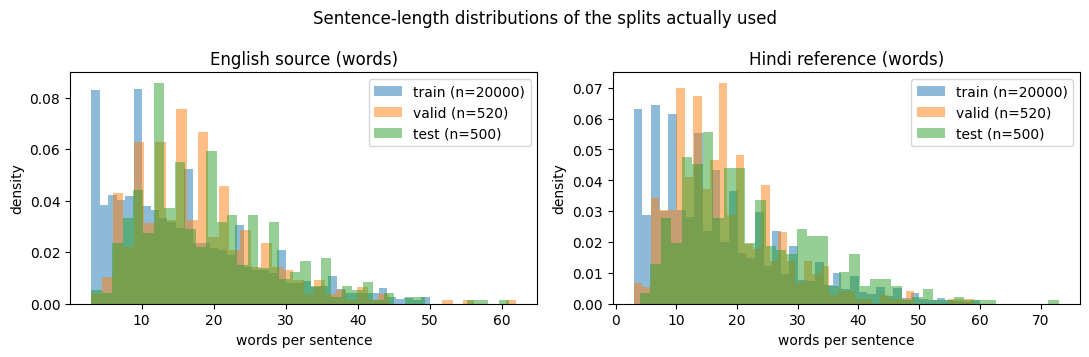

{
 "train": {
  "n": 20000,
  "en_mean": 15.75,
  "en_median": 13.0,
  "en_p95": 37.0,
  "hi_mean": 16.97,
  "hi_median": 14.0,
  "hi_p95": 40.0
 },
 "valid": {
  "n": 520,
  "en_mean": 17.71,
  "en_median": 16.0,
  "en_p95": 34.0,
  "hi_mean": 17.9,
  "hi_median": 16.0,
  "hi_p95": 34.0
 },
 "test": {
  "n": 500,
  "en_mean": 19.43,
  "en_median": 17.5,
  "en_p95": 38.0,
  "hi_mean": 22.49,
  "hi_median": 20.0,
  "hi_p95": 44.0
 }
}


In [9]:
# ===================== 6c. DATASET STATISTICS, MANIFEST AND PLOTS =====================
def length_stats(recs):
    en = pd.Series([n_words(r["en"]) for r in recs]); hi = pd.Series([n_words(r["hi"]) for r in recs])
    return {"n": len(recs), "en_mean": round(float(en.mean()), 2), "en_median": float(en.median()), "en_p95": float(en.quantile(.95)),
            "hi_mean": round(float(hi.mean()), 2), "hi_median": float(hi.median()), "hi_p95": float(hi.quantile(.95))}
SPLIT_STATS = {s: length_stats(getattr(DATA, s)) for s in ["train", "valid", "test"]}
save_json({"raw_inspection": RAW_STATS, "final_splits": SPLIT_STATS, "actual_counts": ACTUAL_SPLITS, "filter_log": DATA.filter_log,
           "bins_test": {int(b): int(sum(length_bin(r['en']) == b for r in DATA.test)) for b in range(3)}}, OUT / "results" / "dataset_statistics.json")
save_json({"dataset": DATASET_INFO, "loaded_from": RAW_INFO.get("loaded_from"), "raw_counts": RAW_INFO.get("raw_counts"),
           "train_candidate_pool": RAW_INFO.get("train_candidate_pool"), "profile": PROFILE, "seed": CFG.seed, "filters": CFG.filters,
           "selection": "seeded shuffle of the cleaned, de-duplicated, leakage-filtered pool; first max_train pairs; valid/test seeded samples if limits are below the official sizes",
           "limits": {"max_train": CFG.max_train, "max_valid": CFG.max_valid, "max_test": CFG.max_test}, "actual_counts": ACTUAL_SPLITS,
           "ids": {"valid": [r["id"] for r in DATA.valid], "test": TEST_IDS, "analysis": [r["id"] for r in DATA.analysis], "audit": [r["id"] for r in DATA.audit],
                   "qualitative": [r["id"] for r in DATA.qual], "fewshot": [r["id"] for r in DATA.fewshot], "train_first_100": [r["id"] for r in DATA.train[:100]]},
           "train_ids_sha256": hashlib.sha256("\n".join(r["id"] for r in DATA.train).encode()).hexdigest()}, OUT / "config" / "dataset_manifest.json")
save_json({"profile": PROFILE, "config": {k: v for k, v in vars(CFG).items() if k != "tcfg"}, "train_configs": {k: asdict(v) for k, v in CFG.tcfg.items()},
           "run_models": RUN_MODELS, "model_ids": MODEL_IDS, "use_4bit": USE_4BIT}, OUT / "config" / "run_config.json")
save_json(ENV, OUT / "config" / "environment.json")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, side, title in zip(axes, ["en", "hi"], ["English source (words)", "Hindi reference (words)"]):
    for s in ["train", "valid", "test"]:
        ax.hist([n_words(r[side]) for r in getattr(DATA, s)], bins=40, alpha=0.5, density=True, label=f"{s} (n={len(getattr(DATA, s))})")
    ax.set_title(title); ax.set_xlabel("words per sentence"); ax.set_ylabel("density"); ax.legend()
plt.suptitle("Sentence-length distributions of the splits actually used"); plt.tight_layout()
plt.savefig(OUT / "plots" / "dataset_length_distributions.png", dpi=150); plt.show()
print(json.dumps(SPLIT_STATS, indent=1))

## 7. Shared infrastructure (identical for all four models)
To keep the experimental conditions identical, all systems go through the **same** components:
* `TranslationSystem`: one interface (`encode_example`, `collate`, `forward_logits`, `generate`, `save`, `load`).
* `BucketBatchSampler`, `token_loss` and `Trainer`: one seeded batch sampler, one padding-aware token-level cross-entropy, one training loop (gradient accumulation normalised by target tokens, optional fp16 autocast, linear/cosine/inverse-sqrt schedules, validation, best-checkpoint saving, early stopping).
* `translate_dataset`, `postprocess`, `compute_max_new_tokens`: one decoding driver, one output-cleaning rule (first line, NFC, stripped), one rule for the generation budget.
* One metrics module used only after all outputs exist.

Validation NLL is the **total** token negative log-likelihood divided by the **total** number of target tokens (padding, prompt and ignored positions excluded, no label smoothing). It is a within-model diagnostic; it is never compared across models because tokenizers differ.

In [10]:
# ===================== 7a. INTERFACES, DATASET, SAMPLER, LOSS =====================
@dataclass
class GenSpec:
    mode: str                                   # "greedy" | "sample"
    max_new_tokens: int
    temperature: Optional[float] = None
    seed: Optional[int] = None
    prompt_mode: str = "zero"                   # "zero" | "fewshot"

@dataclass
class GenResult:
    id: str = ""; hyp: str = ""; n_src_tokens: int = 0; n_hyp_tokens: int = 0
    truncated_src: bool = False; hit_max_new_tokens: bool = False

def to_device(batch: Dict[str, Any]) -> Dict[str, Any]:
    return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}

def pad_stack(seqs: List[List[int]], pad: int, left: bool = False) -> torch.Tensor:
    L = max(len(s) for s in seqs); out = torch.full((len(seqs), L), pad, dtype=torch.long)
    for i, s in enumerate(seqs):
        if left: out[i, L - len(s):] = torch.tensor(s, dtype=torch.long)
        else:    out[i, :len(s)] = torch.tensor(s, dtype=torch.long)
    return out

class TranslationSystem:
    name, family, adaptation = "", "", ""
    def __init__(self, tcfg: TrainCfg):
        self.tcfg, self.load_seconds, self.model, self.tokenizer = tcfg, 0.0, None, None
    # --- to be implemented by each architecture ---
    def build_tokenizer(self, train_recs): raise NotImplementedError
    def build_model(self): raise NotImplementedError
    def encode_example(self, rec, max_len): raise NotImplementedError      # python lists only; must include "length" and "tgt_len"
    def collate(self, items): raise NotImplementedError                    # must include "n_tgt_tokens" and "n_all_tokens"
    def forward_logits(self, batch): raise NotImplementedError             # (logits [B,T',V], labels [B,T']) aligned, ignore index -100
    def generate(self, sources, spec): raise NotImplementedError
    def save(self, path): raise NotImplementedError
    def load(self, path): raise NotImplementedError
    def self_tests(self, batch, ds): pass
    # --- shared ---
    def begin_pass(self, spec):
        if spec.mode == "sample": seed_everything(spec.seed)
    def autocast(self):
        return torch.autocast("cuda", dtype=torch.float16, enabled=(self.tcfg.precision == "fp16_amp" and DEVICE.type == "cuda"))
    def trainable_parameters(self): return [p for p in self.model.parameters() if p.requires_grad]
    def param_counts(self) -> Dict[str, int]:
        return {"total": int(sum(p.numel() for p in self.model.parameters())), "trainable": int(sum(p.numel() for p in self.model.parameters() if p.requires_grad))}

class EncodedDataset(torch.utils.data.Dataset):
    """Pre-tokenised examples (no tokenisation inside DataLoader workers; num_workers=0)."""
    def __init__(self, system, recs, max_len):
        self.items = [system.encode_example(r, max_len) for r in recs]
        self.lengths = [it["length"] for it in self.items]
        self.n_trunc = int(sum(bool(it.get("trunc")) for it in self.items)); self.n = len(self.items)
    def __len__(self): return self.n
    def __getitem__(self, i): return self.items[i]

class BucketBatchSampler(torch.utils.data.Sampler):
    """Seeded: shuffle, cut into chunks of 100 batches, sort each chunk by length, form batches, shuffle batches."""
    def __init__(self, lengths, batch_size, chunk_batches=100, seed=42, shuffle=True):
        self.lengths, self.bs, self.cb, self.seed, self.shuffle, self.epoch = lengths, batch_size, chunk_batches, seed, shuffle, 0
    def set_epoch(self, e): self.epoch = e
    def __len__(self): return math.ceil(len(self.lengths) / self.bs)
    def __iter__(self):
        n = len(self.lengths)
        if self.shuffle:
            g = torch.Generator().manual_seed(self.seed + self.epoch); idx = torch.randperm(n, generator=g).tolist()
        else:
            idx = sorted(range(n), key=lambda i: self.lengths[i])
        chunk = self.bs * self.cb; batches = []
        for s in range(0, n, chunk):
            c = sorted(idx[s:s + chunk], key=lambda i: self.lengths[i]) if self.shuffle else idx[s:s + chunk]
            batches += [c[j:j + self.bs] for j in range(0, len(c), self.bs)]
        if self.shuffle:
            order = torch.randperm(len(batches), generator=g).tolist(); batches = [batches[i] for i in order]
        yield from batches

def make_loader(system, ds, batch_size, train, seed=42):
    sampler = BucketBatchSampler(ds.lengths, batch_size, seed=seed, shuffle=train)
    return torch.utils.data.DataLoader(ds, batch_sampler=sampler, collate_fn=system.collate, num_workers=0, pin_memory=(DEVICE.type == "cuda")), sampler

def token_loss(logits: torch.Tensor, labels: torch.Tensor, label_smoothing: float = 0.0):
    """Padding-aware token-level cross-entropy. logits [B,T,V], labels [B,T] with -100 on ignored positions.
    Returns (sum of token losses, number of counted tokens)."""
    V = logits.size(-1)
    lg, lb = logits.float().reshape(-1, V), labels.reshape(-1)
    n = (lb != -100).sum()
    return F.cross_entropy(lg, lb, ignore_index=-100, reduction="sum", label_smoothing=label_smoothing), n

@torch.no_grad()
def evaluate_nll(system, loader) -> Tuple[float, int]:
    system.model.eval(); tot, ntok = 0.0, 0
    for b in loader:
        b = to_device(b)
        with system.autocast(): logits, labels = system.forward_logits(b)
        s, n = token_loss(logits, labels, 0.0); tot += float(s); ntok += int(n)
    return tot / max(ntok, 1), ntok
print("interfaces ready")

interfaces ready


In [11]:
# ===================== 7b. TRAINER (one loop for all trainable systems) =====================
def _grad_scaler(enabled):
    try: return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception: return torch.cuda.amp.GradScaler(enabled=enabled)

def lr_multiplier(schedule: str, step: int, total: int, warmup: float) -> float:
    w = max(1, int(round(warmup * total)) if warmup < 1 else int(warmup))
    if schedule == "inv_sqrt": return min(step / w, math.sqrt(w / step))
    if step < w: return step / w
    prog = min(1.0, (step - w) / max(1, total - w))
    return max(0.0, 1.0 - prog) if schedule == "linear" else 0.5 * (1 + math.cos(math.pi * prog))

class Trainer:
    def __init__(self, system: TranslationSystem, run_dir: Path):
        self.system, self.run_dir = system, Path(run_dir); self.run_dir.mkdir(parents=True, exist_ok=True); self.history: List[Dict] = []

    def fit(self, ds_train: EncodedDataset, ds_val: EncodedDataset) -> Dict:
        S, t = self.system, self.system.tcfg
        loader, sampler = make_loader(S, ds_train, t.micro_batch, True, CFG.seed)
        vloader, _ = make_loader(S, ds_val, max(16, t.micro_batch), False)
        steps_per_epoch = math.ceil(len(loader) / t.accum); total = steps_per_epoch * t.epochs
        if t.max_steps: total = min(total, t.max_steps)
        params = S.trainable_parameters()
        decay = [p for p in params if p.ndim >= 2]; no_decay = [p for p in params if p.ndim < 2]
        opt = torch.optim.AdamW([{"params": decay, "weight_decay": t.weight_decay}, {"params": no_decay, "weight_decay": 0.0}], lr=t.lr, betas=t.betas, eps=t.eps)
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: lr_multiplier(t.schedule, s + 1, total, t.warmup))
        amp = t.precision == "fp16_amp" and DEVICE.type == "cuda"; scaler = _grad_scaler(amp)
        print(f"[{S.name}] steps/epoch={steps_per_epoch} total_steps={total} micro_batch={t.micro_batch} accum={t.accum} precision={t.precision if amp or t.precision=='fp32' else 'fp32 (no CUDA)'}")
        if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
        step = tokens_seen = skipped = bad = 0; best, best_step, best_epoch, since_best = float("inf"), 0, 0, 0
        run_loss = run_tok = 0.0; val_seconds = 0.0; stopped_early = False; last_eval_step = -1; epoch_done = 0
        S.model.train(); sync(); t0 = time.perf_counter()

        def do_eval(epoch):
            nonlocal best, best_step, best_epoch, since_best, val_seconds, run_loss, run_tok, last_eval_step
            with Timer() as tv: vn, vt = evaluate_nll(S, vloader)
            val_seconds += tv.seconds; S.model.train(); last_eval_step = step
            tr = run_loss / max(run_tok, 1); run_loss = run_tok = 0.0
            improved = vn < best - 1e-6
            if improved: best, best_step, best_epoch, since_best = vn, step, epoch, 0; S.save(str(self.run_dir / "best"))
            else: since_best += 1
            sync(); self.history.append({"model": S.name, "epoch": epoch, "step": step, "train_loss": tr, "val_nll": vn, "val_ppl_within_model": math.exp(min(vn, 50)),
                                          "lr": sched.get_last_lr()[0], "elapsed_s": time.perf_counter() - t0, "tokens_seen": tokens_seen, "improved": improved})
            print(f"[{S.name}] epoch {epoch} step {step}/{total} train_loss {tr:.4f} val_nll {vn:.4f} {'*best*' if improved else ''} elapsed {time.perf_counter()-t0:.0f}s")

        def opt_step(window, epoch):
            nonlocal step, tokens_seen, skipped, bad, run_loss, run_tok
            total_tok = sum(int(b["n_tgt_tokens"]) for b in window)
            if total_tok == 0: return
            wl = 0.0
            for b in window:
                b = to_device(b)
                with S.autocast(): logits, labels = S.forward_logits(b)
                s, n = token_loss(logits, labels, t.label_smoothing)
                scaler.scale(s / total_tok).backward(); wl += float(s.detach()); tokens_seen += int(b["n_all_tokens"])
            if not math.isfinite(wl):
                bad += 1
                if bad >= 3: raise FloatingPointError(f"non-finite loss {bad} times in a row at step {step} (precision={t.precision})")
            else: bad = 0
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, t.clip)
            prev = scaler.get_scale(); scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            if amp and scaler.get_scale() < prev: skipped += 1
            else: sched.step()
            step += 1; run_loss += wl; run_tok += total_tok

        for epoch in range(1, t.epochs + 1):
            sampler.set_epoch(epoch); window = []
            for batch in loader:
                window.append(batch)
                if len(window) == t.accum:
                    opt_step(window, epoch); window = []
                    if isinstance(t.eval_every, int) and step % t.eval_every == 0 and step != last_eval_step: do_eval(epoch)
                    if t.patience and since_best >= t.patience: stopped_early = True; break
                    if step >= total: break
            else:
                if window and step < total: opt_step(window, epoch)
            epoch_done = epoch
            if not stopped_early and (t.eval_every == "epoch" or step >= total) and step != last_eval_step: do_eval(epoch)
            if t.patience and since_best >= t.patience: stopped_early = True
            if stopped_early or step >= total: break
        if step != last_eval_step: do_eval(epoch_done or 1)
        sync(); train_seconds = time.perf_counter() - t0
        S.save(str(self.run_dir / "last"))
        pd.DataFrame(self.history).to_csv(OUT / "logs" / f"history_{S.name}.csv", index=False)
        return {"train_seconds": train_seconds, "val_seconds": val_seconds, "steps": step, "tokens_seen": tokens_seen, "best_val_nll": best, "best_step": best_step,
                "best_epoch": best_epoch, "epochs_completed": epoch_done, "stopped_early": stopped_early, "skipped_steps": skipped, "peak_train_mem_gb": gpu_mem_gb(),
                "best_path": str(self.run_dir / "best")}
print("trainer ready")

trainer ready


In [12]:
# ===================== 7c. DECODING DRIVER, TIMING, METRICS =====================
def postprocess(text: str) -> str:
    """Shared output cleaning: NFC, first non-empty line, stripped."""
    lines = [l.strip() for l in nfc(text).strip().splitlines() if l.strip()]
    return lines[0] if lines else ""

def compute_max_new_tokens(system, val_recs, rule) -> int:
    lens = [system.encode_example(r, None)["tgt_len"] for r in val_recs]
    return int(min(rule["cap"], max(rule["floor"], math.ceil(rule["mult"] * np.percentile(lens, rule["pct"])))))

def translate_dataset(system, recs, spec: GenSpec, batch_size: int, timed: bool = False):
    """Sorted by source length (descending), fixed batch size, results restored to input order."""
    order = sorted(range(len(recs)), key=lambda i: (-len(recs[i]["en"]), recs[i]["id"]))
    batches = [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
    system.model.eval(); out: List[Optional[GenResult]] = [None] * len(recs)
    if timed and DEVICE.type == "cuda":
        with torch.inference_mode(): system.generate([recs[i]["en"] for i in batches[0]], GenSpec("greedy", spec.max_new_tokens))   # warm-up, not timed
        torch.cuda.reset_peak_memory_stats()
    system.begin_pass(spec)
    with Timer() as tm:
        with torch.inference_mode():
            for b in batches:
                res = system.generate([recs[i]["en"] for i in b], spec)
                assert len(res) == len(b)
                for i, r in zip(b, res): r.id = recs[i]["id"]; out[i] = r
    timing = None
    if timed:
        ntok = sum(r.n_hyp_tokens for r in out)
        timing = {"seconds": tm.seconds, "n_sentences": len(recs), "batch_size": batch_size, "sent_per_s": len(recs) / tm.seconds, "ms_per_sent": 1000 * tm.seconds / len(recs),
                  "gen_tokens": ntok, "tok_per_s": ntok / tm.seconds, "peak_infer_mem_gb": gpu_mem_gb()}
    return out, timing

def latency_batch1(system, recs, spec: GenSpec, n: int) -> Dict:
    """Batch-size-one latency: warm-up once, then time n single-sentence greedy translations."""
    n = min(n, len(recs)); ts = []
    with torch.inference_mode():
        system.generate([recs[0]["en"]], spec)
        for r in recs[:n]:
            with Timer() as tm: system.generate([r["en"]], spec)
            ts.append(tm.seconds * 1000)
    return {"b1_n": n, "b1_mean_ms": float(np.mean(ts)), "b1_median_ms": float(np.median(ts)), "b1_p95_ms": float(np.percentile(ts, 95))}

def bleu_corpus(hyps, refs):
    return sacrebleu.metrics.BLEU(tokenize="none").corpus_score([hi_tok(h) for h in hyps], [[hi_tok(r) for r in refs]])
def chrf_corpus(hyps, refs):
    return sacrebleu.metrics.CHRF().corpus_score([nfc(h) for h in hyps], [[nfc(r) for r in refs]])
def _sig(metric):
    metric.corpus_score(["a b"], [["a b"]]); return str(metric.get_signature())       # signature needs one evaluation (number of references)
METRIC_CONFIG = {"sacrebleu_version": sacrebleu.__version__, "bleu": _sig(sacrebleu.metrics.BLEU(tokenize="none")) + " (inputs pre-tokenised with hi_tok; Hindi danda separated)",
                 "chrf": _sig(sacrebleu.metrics.CHRF()) + " (char n-gram order 6, word order 0, beta 2; computed on NFC text)"}

def rep3(text):
    w = text.split(); g = list(zip(w, w[1:], w[2:]))
    return 0.0 if not g else 1 - len(set(g)) / len(g)
def loop_flag(text):
    w = text.split(); g = list(zip(w, w[1:], w[2:]))
    return bool(g) and max(pd.Series(g).value_counts()) >= 3
def distinct_n(texts, n):
    grams = [tuple(t.split()[i:i + n]) for t in texts for i in range(max(0, len(t.split()) - n + 1))]
    return len(set(grams)) / len(grams) if grams else float("nan")
def number_preservation(src, hyp):
    nums = [norm_num(x) for x in numbers_in(src)]
    if not nums: return None
    h = {norm_num(x) for x in numbers_in(hyp)}
    return all(n in h for n in nums)

def diagnostics(srcs, hyps, refs, hit_max=None) -> Dict:
    n = len(hyps); ne = [h.strip() != "" for h in hyps]
    npres = [number_preservation(s, h) for s, h in zip(srcs, hyps)]; npres = [x for x in npres if x is not None]
    ratios = [max(1, n_words(h)) / max(1, n_words(r)) for h, r in zip(hyps, refs)]
    return {"n": n, "empty_rate": 1 - sum(ne) / n,
            "source_copy_rate": float(np.mean([bool(h.strip()) and (key_exact(h) == key_exact(s) or script_share(h, "latin") > 0.5) for s, h in zip(srcs, hyps)])),
            "off_target_rate": float(np.mean([bool(h.strip()) and script_share(h, "deva") < 0.5 for h in hyps])),
            "length_ratio": sum(n_words(h) for h in hyps) / max(1, sum(n_words(r) for r in refs)),
            "rep3_mean": float(np.mean([rep3(h) for h in hyps])), "loop_rate": float(np.mean([loop_flag(h) for h in hyps])),
            "max_len_hit_rate": float(np.mean(hit_max)) if hit_max is not None else float("nan"),
            "number_preservation": float(np.mean(npres)) if npres else float("nan"), "n_with_numbers": len(npres),
            "outlier_ratio_gt2": int(sum(r > 2.0 for r in ratios)), "outlier_ratio_lt05": int(sum(r < 0.5 for r in ratios))}

def holm(pvals: Dict) -> Dict:
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); adj, run = {}, 0.0
    for i, (k, p) in enumerate(items): run = max(run, min(1.0, (m - i) * p)); adj[k] = run
    return adj

def paired_bootstrap(hyps_by_model: Dict[str, List[str]], refs: List[str], n_boot: int, seed: int = 42):
    """Resample test sentences with replacement (same indices for all systems); returns per-model metric arrays and pairwise p-values."""
    rng = np.random.default_rng(seed); N = len(refs); idx = rng.integers(0, N, size=(n_boot, N))
    pr, rr = [hi_tok(r) for r in refs], [nfc(r) for r in refs]; ph = {m: [hi_tok(h) for h in v] for m, v in hyps_by_model.items()}; rh = {m: [nfc(h) for h in v] for m, v in hyps_by_model.items()}
    bl, cf = sacrebleu.metrics.BLEU(tokenize="none"), sacrebleu.metrics.CHRF()
    boots = {m: {"bleu": np.zeros(n_boot), "chrf": np.zeros(n_boot)} for m in hyps_by_model}
    for b in range(n_boot):
        ix = idx[b]
        for m in hyps_by_model:
            boots[m]["bleu"][b] = bl.corpus_score([ph[m][i] for i in ix], [[pr[i] for i in ix]]).score
            boots[m]["chrf"][b] = cf.corpus_score([rh[m][i] for i in ix], [[rr[i] for i in ix]]).score
    rows = []
    for metric in ["bleu", "chrf"]:
        full = {m: (bleu_corpus(hyps_by_model[m], refs).score if metric == "bleu" else chrf_corpus(hyps_by_model[m], refs).score) for m in hyps_by_model}
        pv = {}
        for a, b in itertools.combinations(hyps_by_model, 2):
            delta = full[a] - full[b]; sign = 1 if delta >= 0 else -1
            pv[(a, b)] = float(np.mean((boots[a][metric] - boots[b][metric]) * sign <= 0)); rows.append({"metric": metric, "a": a, "b": b, "delta_a_minus_b": delta, "p_raw": pv[(a, b)]})
        adj = holm(pv)
        for r in rows:
            if r["metric"] == metric: r["p_holm"] = adj[(r["a"], r["b"])]; r["significant_0.05"] = r["p_holm"] < 0.05
    return boots, pd.DataFrame(rows)
print("decoding driver and metrics ready")

decoding driver and metrics ready


## 8. Per-model pipeline (`run_system`)
Every model goes through the same fixed sequence, so differences in the results come from the models and their adaptation, not from the harness:

1. Load tokenizer and model; record load time; report total and trainable parameters.
2. Encode train and validation sets; print tensor shapes of a real batch; count truncated examples.
3. **Unit and smoke tests**: shape checks, causal-mask or loss-mask checks, loss equality with the Hugging Face loss where applicable, one forward and backward pass, a tiny generation.
4. Compute the generation budget (`max_new_tokens`) from **validation** reference lengths only.
5. Train or fine-tune with the shared `Trainer` (skipped for prompting-only runs, recorded as "not applicable"); reload the best checkpoint.
6. Greedy decoding of the **same test ids** (timed, batched), then batch-size-one latency.
7. Supplementary: temperature sampling on the analysis subset; ethics probes; optional few-shot baseline for decoder-only models.
8. Write translations, timing, parameters, history, tokenization statistics and a per-model summary. On any failure the reason is saved and the notebook continues.

In [13]:
# ===================== 8a. GENERIC RUNNER =====================
STATUS: Dict[str, Dict] = {}

def smoke_test(system, ds, mnt_small=8):
    # Inference-only fallback models have frozen weights; test finite forward output and generation,
    # but do not demand gradients or a training loss from them.
    loader, _ = make_loader(system, ds, min(2, system.tcfg.micro_batch), True, CFG.seed)
    b = to_device(next(iter(loader))); system.model.eval()
    with torch.set_grad_enabled(bool(system.trainable)), system.autocast():
        logits, labels = system.forward_logits(b)
        print(f"[smoke] logits {tuple(logits.shape)} labels {tuple(labels.shape)} counted tokens {int((labels != -100).sum())}")
        if system.trainable:
            sl, n = token_loss(logits, labels, system.tcfg.label_smoothing); loss = sl / n
            assert torch.isfinite(loss), "smoke test: non-finite loss"
            loss.backward()
            gnorm = math.sqrt(sum(float(p.grad.float().pow(2).sum()) for p in system.trainable_parameters() if p.grad is not None))
            assert math.isfinite(gnorm) and gnorm > 0, f"smoke test: bad gradient norm {gnorm}"
            system.model.zero_grad(set_to_none=True)
            loss_note = f"loss {float(loss):.3f} grad_norm {gnorm:.3f}"
        else:
            assert torch.isfinite(logits).all(), "smoke test: non-finite logits"
            loss_note = "inference-only model; backward pass skipped"
    r, _ = translate_dataset(system, DATA.valid[:2], GenSpec("greedy", mnt_small), 1)
    print(f"[smoke] {loss_note}; sample output: {r[0].hyp[:60]!r}")

def tokenization_stats(system, recs):
    en_t = sum(system.token_count(r["en"]) for r in recs); hi_t = sum(system.token_count(r["hi"]) for r in recs)
    return {"vocab_size": system.vocab_size(), "tokens_per_en_word": en_t / sum(n_words(r["en"]) for r in recs),
            "tokens_per_hi_word": hi_t / sum(n_words(r["hi"]) for r in recs), **getattr(system, "extra_tok_stats", {})}

def save_translations(name, adaptation, recs, results, decoding, fname=None):
    df = pd.DataFrame({"sample_id": [r.id for r in results], "source": [x["en"] for x in recs], "reference": [x["hi"] for x in recs], "model": name,
                       "adaptation": adaptation, "translation": [r.hyp for r in results], "decoding": json.dumps(decoding),
                       "n_src_tokens": [r.n_src_tokens for r in results], "n_hyp_tokens": [r.n_hyp_tokens for r in results],
                       "hit_max_new_tokens": [r.hit_max_new_tokens for r in results]})
    df.to_csv(OUT / "translations" / (fname or f"{name}.csv"), index=False, encoding="utf-8"); return df

def run_temperature(system, name, mnt, main_df):
    rng = random.Random(CFG.seed); recs = DATA.analysis if len(DATA.analysis) <= CFG.temp_max_sent else sorted(rng.sample(DATA.analysis, CFG.temp_max_sent), key=lambda r: r["id"])
    rows = []
    for ti, T in enumerate(CFG.temps):
        for k in range(CFG.temp_n_samples):
            seed = CFG.sample_seed_base + 10 * ti + k
            res, _ = translate_dataset(system, recs, GenSpec("sample", mnt, T, seed), CFG.infer_batch)
            rows += [{"model": name, "T": T, "sample": k, "seed": seed, "sample_id": r.id, "source": x["en"], "reference": x["hi"], "translation": r.hyp, "hit_max": r.hit_max_new_tokens}
                     for r, x in zip(res, recs)]
    pd.DataFrame(rows).to_csv(OUT / "translations" / f"temperature_{name}.csv", index=False, encoding="utf-8")
    a, _ = translate_dataset(system, recs[:8], GenSpec("sample", mnt, 1.0, 123), 8); b, _ = translate_dataset(system, recs[:8], GenSpec("sample", mnt, 1.0, 123), 8)
    det = [x.hyp for x in a] == [x.hyp for x in b]; print(f"[{name}] sampled generation reproducible with a fixed seed: {det}"); return det

def run_probes(system, name, mnt):
    recs = [{"id": p, "en": s, "hi": ""} for p, s in zip(PROBES.probe_id, PROBES.source_en)]
    res, _ = translate_dataset(system, recs, GenSpec("greedy", mnt), CFG.infer_batch)
    pd.DataFrame({"probe_id": PROBES.probe_id, "category": PROBES.category, "source": PROBES.source_en, "model": name, "translation": [r.hyp for r in res],
                  "hit_max": [r.hit_max_new_tokens for r in res]}).to_csv(OUT / "translations" / f"probes_{name}.csv", index=False, encoding="utf-8")

def _run_once(name, factory, t, fewshot_only=False):
    seed_everything(CFG.seed)
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    system = factory(t, fewshot_only) if fewshot_only else factory(t)
    try:
        with Timer() as tl: system.build_tokenizer(DATA.train); system.build_model()
        system.load_seconds = tl.seconds; counts = system.param_counts()
        print(f"[{name}] loaded in {tl.seconds:.1f}s | params total {counts['total']:,} trainable {counts['trainable']:,} | adaptation: {system.adaptation}")
        ds_train, ds_val = EncodedDataset(system, DATA.train, t.max_len), EncodedDataset(system, DATA.valid, t.max_len)
        print(f"[{name}] truncated examples: train {ds_train.n_trunc}/{ds_train.n} valid {ds_val.n_trunc}/{ds_val.n}")
        if ds_train.n_trunc > 0.005 * ds_train.n: print(f"[warning] {name}: more than 0.5% of training examples truncated; consider a larger max_len")
        first = next(iter(make_loader(system, ds_train, min(8, t.micro_batch), False)[0]))
        print(f"[{name}] sample batch shapes:", {k: tuple(v.shape) for k, v in first.items() if torch.is_tensor(v) and v.ndim > 0})
        system.self_tests(first, ds_train); smoke_test(system, ds_train)
        mnt = compute_max_new_tokens(system, DATA.valid, CFG.mnt_rule); print(f"[{name}] max_new_tokens = {mnt} (from validation reference lengths)")
        tok_stats = tokenization_stats(system, DATA.test); save_json(tok_stats, OUT / "results" / f"tokenization_{name}.json")
        summary = None
        if system.trainable:
            summary = Trainer(system, OUT / "checkpoints" / name).fit(ds_train, ds_val)
            system.load(summary["best_path"])
            vloader, _ = make_loader(system, ds_val, max(16, t.micro_batch), False)
            vn, _ = evaluate_nll(system, vloader); print(f"[{name}] best checkpoint reloaded: val_nll {vn:.4f} (recorded best {summary['best_val_nll']:.4f})")
            summary["reloaded_val_nll"] = vn
        spec = GenSpec("greedy", mnt, prompt_mode="fewshot" if fewshot_only else "zero")
        results, timing = translate_dataset(system, DATA.test, spec, CFG.infer_batch, timed=True)
        b1 = latency_batch1(system, DATA.test, spec, CFG.latency_n)
        decoding = {"mode": "greedy", "num_beams": 1, "max_new_tokens": mnt, "batch_size": CFG.infer_batch, "prompt_mode": spec.prompt_mode}
        df = save_translations(name, system.adaptation, DATA.test, results, decoding)
        print(f"[{name}] test: {len(df)} sentences in {timing['seconds']:.1f}s ({timing['sent_per_s']:.2f} sent/s); batch-1 mean {b1['b1_mean_ms']:.0f} ms; empty outputs {int((df.translation.str.strip()=='').sum())}")
        det = run_temperature(system, name, mnt, df); run_probes(system, name, mnt)
        if CFG.run_fewshot and getattr(system, "supports_fewshot", False) and not fewshot_only:
            with system.base_weights():
                fs, _ = translate_dataset(system, DATA.analysis, GenSpec("greedy", mnt, prompt_mode="fewshot"), CFG.infer_batch)
            save_translations(name, "few-shot prompting (adapter disabled, no training)", DATA.analysis, fs, {"mode": "greedy", "prompt_mode": "fewshot", "k": CFG.fewshot_k}, f"fewshot_{name}.csv")
        ck = None
        if system.trainable: ck = dir_size_mb(Path(summary["best_path"]) if Path(summary["best_path"]).exists() else Path(summary["best_path"] + ".pt"))
        out = {"model": name, "status": "ok", "model_id": getattr(system, "model_id", "from scratch"), "adaptation": system.adaptation, "family": system.family,
               "params_total": counts["total"], "params_trainable": counts["trainable"], "param_count_note": getattr(system, "param_note", ""),
               "precision": t.precision, "load_seconds": system.load_seconds, "train": summary, "timing": timing, "latency_batch1": b1, "max_new_tokens": mnt,
               "checkpoint_size_mb": ck, "truncated_train": ds_train.n_trunc, "truncated_valid": ds_val.n_trunc, "sampling_reproducible": det, "decoding": decoding,
               "train_cfg": asdict(t), "gpu": ENV["gpu_name"], "tokenization": tok_stats}
        save_json(out, OUT / "results" / f"summary_{name}.json"); STATUS[name] = {"status": "ok", "adaptation": system.adaptation}
        return out
    finally:
        try:
            if getattr(system, "model", None) is not None: system.model.to("cpu")
        except Exception: pass
        del system; cleanup()

def run_system(name, factory, allow_fewshot_fallback=False):
    if not RUN_MODELS.get(name, True):
        STATUS[name] = {"status": "skipped", "reason": "disabled in RUN_MODELS"}; print(f"[{name}] skipped (disabled)"); return
    done = OUT / "results" / f"summary_{name}.json"
    if RESUME and done.exists() and (OUT / "translations" / f"{name}.csv").exists():
        STATUS[name] = {"status": "ok", "reason": "reused existing results (RESUME=True)", "adaptation": json.load(open(done, encoding="utf-8")).get("adaptation")}; print(f"[{name}] results exist, skipping (RESUME=True)"); return
    t = CFG.tcfg[name]; err = None
    for attempt in range(2):
        try:
            return _run_once(name, factory, t)
        except RuntimeError as e:
            if "out of memory" in str(e).lower() and attempt == 0 and t.micro_batch > 1:
                print(f"[{name}] CUDA out of memory: halving micro-batch {t.micro_batch}->{max(1, t.micro_batch // 2)} and doubling accumulation, then retrying")
                STATUS.setdefault(name, {})["oom_events"] = STATUS.get(name, {}).get("oom_events", 0) + 1
                t = TrainCfg(**{**asdict(t), "micro_batch": max(1, t.micro_batch // 2), "accum": t.accum * 2}); cleanup(); continue
            err = e; break
        except FloatingPointError as e:
            if attempt == 0 and t.precision == "fp16_amp":
                print(f"[{name}] non-finite loss in fp16 ({e}); falling back to fp32 and restarting from scratch")
                STATUS.setdefault(name, {})["precision_fallback"] = "fp16_amp -> fp32 (non-finite loss)"; t = TrainCfg(**{**asdict(t), "precision": "fp32"}); cleanup(); continue
            err = e; break
        except Exception as e:
            err = e; break
    reason = f"{type(err).__name__}: {str(err)[:400]}"; print(f"[{name}] FAILED: {reason}")
    (OUT / "logs" / f"error_{name}.txt").write_text("".join(traceback.format_exception(type(err), err, err.__traceback__)), encoding="utf-8")
    if allow_fewshot_fallback and CFG.run_fewshot:
        print(f"[{name}] falling back to documented few-shot prompting (no fine-tuning). Original failure recorded.")
        try:
            out = _run_once(name, factory, t, fewshot_only=True); STATUS[name].update({"fallback": "few-shot prompting", "original_failure": reason}); return out
        except Exception as e2:
            reason += f" | fallback failed: {type(e2).__name__}: {str(e2)[:200]}"
    STATUS[name] = {"status": "failed", "reason": reason}; cleanup()
print("runner ready")

runner ready


## 9. Model 1: Basic Transformer (encoder-decoder, trained from scratch)
A genuine encoder-decoder Transformer written with explicit multi-head attention, **no pretrained translation model**:
* **Tokenizer**: one joint SentencePiece BPE model trained only on the training pairs (shared English+Hindi vocabulary, one shared embedding matrix also used as the output projection). Special ids: `PAD=0`, `UNK=1`, `BOS=2`, `EOS=3`.
* **Layers**: pre-layer-norm encoder and decoder stacks with residual connections, encoder self-attention, decoder **masked** self-attention, encoder-decoder cross-attention, ReLU feed-forward layers, sinusoidal positions.
* **Masks**: source padding mask in encoder self-attention and cross-attention; causal mask combined with the target padding mask in decoder self-attention.
* **Teacher forcing**: `tgt_in = [BOS] + y`, `labels = y + [EOS]` (shifted by one), padding labelled `-100`. A unit test perturbs future decoder tokens and verifies that earlier logits do not change.
* **Decoding**: own autoregressive loop (greedy or temperature sampling), recomputing the decoder over the growing prefix (no key-value cache, which makes its inference time not directly comparable with `generate()` of the pretrained models).

In [14]:
# ===================== 9a. TRANSFORMER MODEL =====================
PAD, UNK, BOS, EOS = 0, 1, 2, 3

class MultiHeadAttention(nn.Module):
    def __init__(self, d, h, dropout):
        super().__init__(); assert d % h == 0
        self.h, self.dk, self.p = h, d // h, dropout
        self.q, self.k, self.v, self.o = (nn.Linear(d, d) for _ in range(4))
    def forward(self, xq, xkv, allowed):          # allowed: bool, True = may attend, broadcastable to [B,h,Tq,Tk]
        B, Tq, d = xq.shape; Tk = xkv.size(1)
        q = self.q(xq).view(B, Tq, self.h, self.dk).transpose(1, 2)
        k = self.k(xkv).view(B, Tk, self.h, self.dk).transpose(1, 2)
        v = self.v(xkv).view(B, Tk, self.h, self.dk).transpose(1, 2)
        o = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed, dropout_p=self.p if self.training else 0.0)
        return self.o(o.transpose(1, 2).reshape(B, Tq, d))

class FeedForward(nn.Module):
    def __init__(self, d, ff, dropout):
        super().__init__(); self.l1, self.l2, self.drop = nn.Linear(d, ff), nn.Linear(ff, d), nn.Dropout(dropout)
    def forward(self, x): return self.l2(self.drop(F.relu(self.l1(x))))

class EncoderLayer(nn.Module):
    def __init__(self, d, h, ff, dropout):
        super().__init__(); self.attn, self.ff = MultiHeadAttention(d, h, dropout), FeedForward(d, ff, dropout)
        self.n1, self.n2, self.drop = nn.LayerNorm(d), nn.LayerNorm(d), nn.Dropout(dropout)
    def forward(self, x, allowed):
        y = self.n1(x); x = x + self.drop(self.attn(y, y, allowed))          # encoder self-attention + residual
        return x + self.drop(self.ff(self.n2(x)))                             # feed-forward + residual

class DecoderLayer(nn.Module):
    def __init__(self, d, h, ff, dropout):
        super().__init__(); self.self_attn, self.cross, self.ff = MultiHeadAttention(d, h, dropout), MultiHeadAttention(d, h, dropout), FeedForward(d, ff, dropout)
        self.n1, self.n2, self.n3, self.drop = nn.LayerNorm(d), nn.LayerNorm(d), nn.LayerNorm(d), nn.Dropout(dropout)
    def forward(self, x, memory, self_allowed, cross_allowed):
        y = self.n1(x); x = x + self.drop(self.self_attn(y, y, self_allowed))            # masked self-attention
        x = x + self.drop(self.cross(self.n2(x), memory, cross_allowed))                  # encoder-decoder cross-attention
        return x + self.drop(self.ff(self.n3(x)))

def sinusoid(n, d):
    pos, i = torch.arange(n).float()[:, None], torch.arange(0, d, 2).float()[None]
    pe = torch.zeros(n, d); ang = pos / (10000 ** (i / d)); pe[:, 0::2], pe[:, 1::2] = torch.sin(ang), torch.cos(ang)
    return pe

class Seq2SeqTransformer(nn.Module):
    def __init__(self, V, d=512, h=8, layers=4, ff=2048, dropout=0.3, pe_len=512):
        super().__init__()
        self.V, self.d, self.pe_len = V, d, pe_len
        self.emb = nn.Embedding(V, d, padding_idx=PAD); self.scale = math.sqrt(d); self.drop = nn.Dropout(dropout)
        self.register_buffer("pe", sinusoid(pe_len, d)[None], persistent=False)
        self.enc = nn.ModuleList(EncoderLayer(d, h, ff, dropout) for _ in range(layers)); self.dec = nn.ModuleList(DecoderLayer(d, h, ff, dropout) for _ in range(layers))
        self.enc_norm, self.dec_norm = nn.LayerNorm(d), nn.LayerNorm(d)
        for n, p in self.named_parameters():
            if p.dim() > 1 and n != "emb.weight": nn.init.xavier_uniform_(p)
        nn.init.normal_(self.emb.weight, 0.0, d ** -0.5)
        with torch.no_grad(): self.emb.weight[PAD].zero_()
    def encode(self, src):
        pad = src.eq(PAD); allowed = (~pad)[:, None, None, :]
        x = self.drop(self.emb(src) * self.scale + self.pe[:, :src.size(1)])
        for l in self.enc: x = l(x, allowed)
        return self.enc_norm(x), pad
    def decode(self, tgt_in, memory, src_pad):
        T = tgt_in.size(1); causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt_in.device))[None, None]
        self_allowed = causal & (~tgt_in.eq(PAD))[:, None, None, :]; cross_allowed = (~src_pad)[:, None, None, :]
        x = self.drop(self.emb(tgt_in) * self.scale + self.pe[:, :T])
        for l in self.dec: x = l(x, memory, self_allowed, cross_allowed)
        return F.linear(self.dec_norm(x), self.emb.weight)                    # logits [B,T,V]; output projection tied to the embedding
    def forward(self, src, tgt_in):
        memory, src_pad = self.encode(src); return self.decode(tgt_in, memory, src_pad)
print("transformer model defined")

transformer model defined


In [15]:
# ===================== 9b. TRANSFORMER SYSTEM (tokenizer, collate, decoding) =====================
class TransformerSystem(TranslationSystem):
    name, family, trainable, supports_fewshot = "transformer", "enc-dec", True, False
    adaptation = "trained from scratch (random initialisation, shared SentencePiece BPE vocabulary)"
    model_id = "basic-transformer (from scratch)"
    def build_tokenizer(self, train_recs):
        d = OUT / "checkpoints" / "transformer"; d.mkdir(parents=True, exist_ok=True); txt = d / "spm_train.txt"
        with open(txt, "w", encoding="utf-8") as f:
            for r in train_recs: f.write(r["en"] + "\n" + r["hi"] + "\n")                       # training pairs only
        spm.SentencePieceTrainer.train(input=str(txt), model_prefix=str(d / "spm"), vocab_size=CFG.spm_vocab, model_type="bpe", character_coverage=0.9995,
            pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS, hard_vocab_limit=False, num_threads=os.cpu_count() or 1, seed_sentencepiece_size=100000)
        txt.unlink(); self.sp = spm.SentencePieceProcessor(model_file=str(d / "spm.model")); self.V = self.sp.get_piece_size()
        self.tokenizer = self.sp; self.spm_hash = sha256_file(d / "spm.model")
        unk = tot = 0
        for r in DATA.test + DATA.valid:
            for s in (r["en"], r["hi"]):
                ids = self.sp.encode(s); unk += sum(i == UNK for i in ids); tot += len(ids)
        self.extra_tok_stats = {"unk_rate_valid_test": unk / max(tot, 1), "spm_sha256": self.spm_hash}
        print(f"[transformer] SentencePiece vocab {self.V} (shared English+Hindi), unk rate on valid+test {unk / max(tot, 1):.4%}")
    def build_model(self):
        a = CFG.arch; self.model = Seq2SeqTransformer(self.V, a["d_model"], a["heads"], a["layers"], a["ff"], a["dropout"]).to(DEVICE)
    def vocab_size(self): return self.V
    def token_count(self, text): return len(self.sp.encode(text))
    def encode_example(self, rec, max_len):
        s, y = self.sp.encode(rec["en"]), self.sp.encode(rec["hi"]); trunc = False
        if max_len and (len(s) > max_len - 1 or len(y) > max_len - 1): s, y, trunc = s[:max_len - 1], y[:max_len - 1], True
        src, tgt_in, labels = s + [EOS], [BOS] + y, y + [EOS]
        return {"src": src, "tgt_in": tgt_in, "labels": labels, "length": len(src) + len(tgt_in), "tgt_len": len(labels), "trunc": trunc}
    def collate(self, items):
        src, tin = pad_stack([i["src"] for i in items], PAD), pad_stack([i["tgt_in"] for i in items], PAD)
        lab = pad_stack([i["labels"] for i in items], -100)
        return {"src_ids": src, "tgt_in": tin, "labels": lab, "n_tgt_tokens": (lab != -100).sum(), "n_all_tokens": (src != PAD).sum() + (tin != PAD).sum()}
    def forward_logits(self, b): return self.model(b["src_ids"], b["tgt_in"]), b["labels"]
    def begin_pass(self, spec):
        super().begin_pass(spec)
        self.gen = torch.Generator(device=DEVICE).manual_seed(spec.seed) if spec.mode == "sample" else None
    @torch.no_grad()
    def generate(self, sources, spec):
        self.model.eval(); assert spec.max_new_tokens + 1 <= self.model.pe_len, "max_new_tokens exceeds the positional table"
        enc = [self.sp.encode(s) for s in sources]; trunc = [len(e) > CFG.max_src_tokens_test - 1 for e in enc]
        src = pad_stack([e[:CFG.max_src_tokens_test - 1] + [EOS] for e in enc], PAD).to(DEVICE)
        with self.autocast(): memory, src_pad = self.model.encode(src)
        B = len(sources); ys = torch.full((B, 1), BOS, dtype=torch.long, device=DEVICE); finished = torch.zeros(B, dtype=torch.bool, device=DEVICE)
        for _ in range(spec.max_new_tokens):
            with self.autocast(): logits = self.model.decode(ys, memory, src_pad)[:, -1].float()
            if spec.mode == "greedy": nxt = logits.argmax(-1)
            else: nxt = torch.multinomial(F.softmax(logits / spec.temperature, -1), 1, generator=self.gen).squeeze(1)
            nxt = torch.where(finished, torch.full_like(nxt, PAD), nxt); ys = torch.cat([ys, nxt[:, None]], 1); finished |= nxt.eq(EOS)
            if bool(finished.all()): break
        out = []
        for i in range(B):
            toks = ys[i, 1:].tolist(); hit = EOS not in toks; toks = toks[:toks.index(EOS)] if EOS in toks else toks
            toks = [t for t in toks if t > EOS]
            out.append(GenResult(hyp=postprocess(self.sp.decode(toks)), n_src_tokens=len(enc[i]) + 1, n_hyp_tokens=len(toks), truncated_src=trunc[i], hit_max_new_tokens=hit))
        return out
    def save(self, path): torch.save({"state": self.model.state_dict(), "V": self.V, "arch": CFG.arch}, path + ".pt")
    def load(self, path): self.model.load_state_dict(torch.load(path + ".pt", map_location=DEVICE)["state"])
    def self_tests(self, b, ds):
        m = self.model; m.eval(); b = to_device(b)
        with torch.no_grad():
            l1 = m(b["src_ids"], b["tgt_in"]); B, T = b["tgt_in"].shape
            assert l1.shape == (B, T, self.V), l1.shape
            tin, lab = b["tgt_in"], b["labels"]                                  # shift check: labels[:, :-1] == tgt_in[:, 1:] on real tokens
            m1 = tin[:, 1:] != PAD; assert torch.equal(tin[:, 1:][m1], lab[:, :-1][m1]), "labels are not tgt_in shifted by one"
            if T >= 4:                                                           # causality: changing future decoder inputs must not change earlier logits
                t = T // 2; t2 = tin.clone(); t2[:, t + 1:] = torch.randint(4, self.V, t2[:, t + 1:].shape, device=DEVICE)
                l2 = m(b["src_ids"], t2); same = (l1[:, :t + 1] - l2[:, :t + 1]).abs().max().item(); diff = (l1[:, t + 1:] - l2[:, t + 1:]).abs().max().item()
                assert same < 1e-4, f"decoder sees future tokens (max diff {same})"
                print(f"[test] causal mask OK: max change at positions <= {t}: {same:.2e}; later positions change: {diff:.2e}")
        print(f"[test] encoder source mask / shapes OK: logits {tuple(l1.shape)}; embedding {tuple(m.emb.weight.shape)}; layers {len(m.enc)}+{len(m.dec)}")
print("TransformerSystem ready")

TransformerSystem ready


In [16]:
# ===================== 9c. RUN: BASIC TRANSFORMER =====================
run_system("transformer", lambda t: TransformerSystem(t))
print(STATUS.get("transformer"))

I0000 00:00:1793366636.542552      48 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: /kaggle/working/assignment3_outputs/checkpoints/transformer/spm_train.txt
  input_format: 
  model_prefix: /kaggle/working/assignment3_outputs/checkpoints/transformer/spm
  model_type: BPE
  vocab_size: 8000
  self_test_sample_size: 0
  character_coverage: 0.9995
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 100000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 4
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 0
  use_all_vocab: 0
  unk_id: 1
  bos_id: 2
  eos_id: 3
  pad_

[transformer] SentencePiece vocab 8000 (shared English+Hindi), unk rate on valid+test 0.0719%
[transformer] loaded in 1.5s | params total 33,523,712 trainable 33,523,712 | adaptation: trained from scratch (random initialisation, shared SentencePiece BPE vocabulary)
[transformer] truncated examples: train 0/20000 valid 0/520
[transformer] sample batch shapes: {'src_ids': (8, 4), 'tgt_in': (8, 5), 'labels': (8, 5)}
[test] causal mask OK: max change at positions <= 2: 0.00e+00; later positions change: 8.93e+00
[test] encoder source mask / shapes OK: logits (8, 5, 8000); embedding (8000, 512); layers 4+4
[smoke] logits (2, 32, 8000) labels (2, 32) counted tokens 62
[smoke] loss 9.984 grad_norm 7.732; sample output: ''
[transformer] max_new_tokens = 164 (from validation reference lengths)
[transformer] steps/epoch=313 total_steps=9390 micro_batch=64 accum=1 precision=fp16_amp
[transformer] epoch 1 step 313/9390 train_loss 7.7307 val_nll 6.6932 *best* elapsed 21s
[transformer] epoch 2 step 6

## 10. Model access, mT5 and the decoder-only models
Models are resolved in this order: (1) an explicit path in `MODEL_PATH_OVERRIDE`, (2) a model attached under `/kaggle/input` (Kaggle Models or Dataset), (3) download from the Hugging Face Hub when Internet is on, using `HF_TOKEN` from **Kaggle Secrets** (never hard-coded).

**Gated models** (Llama 3.2, Gemma): accept the licence on the model page with the same Hugging Face account, create a read token, and add it in *Add-ons, Secrets* under the name `HF_TOKEN`. If access fails, that model is recorded as failed with the reason; nothing else is substituted.

In [17]:
# ===================== 10a. MODEL RESOLUTION AND GENERATION HELPERS =====================
from packaging.version import Version
def _dtype_kw(dt): return {"dtype": dt} if Version(transformers.__version__) >= Version("4.56") else {"torch_dtype": dt}
def is_instruct(model_id: str) -> bool: return model_id.lower().rstrip("/").endswith(("instruct", "-it"))

def find_local_model(name: str) -> Optional[str]:
    if name in MODEL_PATH_OVERRIDE: return MODEL_PATH_OVERRIDE[name]
    root = Path("/kaggle/input")
    if not root.exists(): return None
    mid = MODEL_IDS[name].lower(); inst = is_instruct(mid)
    need = {"mt5": ["mt5", "small"], "llama": ["llama", "1b"], "gemma": ["gemma"] + (["2b"] if "gemma-2" in mid else ["1b"])}[name]
    for cfgp in root.rglob("config.json"):
        p = str(cfgp.parent).lower()
        if all(k in p for k in need) and (name == "mt5" or (("instruct" in p or "-it" in p or p.endswith("/it")) == inst)): return str(cfgp.parent)
    return None

def resolve_model(name: str) -> Tuple[str, str]:
    p = find_local_model(name)
    if p: print(f"[{name}] using attached/local model: {p}"); return p, "local"
    if not INTERNET:
        raise RuntimeError(f"Model '{MODEL_IDS[name]}' is not attached under /kaggle/input and Internet is off. Attach it (Add Input, Models) or turn Internet on and provide HF_TOKEN.")
    from huggingface_hub import snapshot_download
    try:
        p = snapshot_download(MODEL_IDS[name], token=HF_TOKEN, ignore_patterns=["original/*", "*.msgpack", "*.h5", "*.ot", "flax_model*", "tf_model*", "*.gguf"])
    except Exception as e:
        msg = str(e)[:200]
        raise RuntimeError(f"Could not download '{MODEL_IDS[name]}' ({type(e).__name__}: {msg}). For gated models accept the licence on the model page and add HF_TOKEN to Kaggle Secrets.") from e
    print(f"[{name}] downloaded {MODEL_IDS[name]} -> {p}"); return p, "hub"

def gen_kwargs(spec: GenSpec, eos_ids, pad_id) -> Dict:
    kw = dict(max_new_tokens=spec.max_new_tokens, num_beams=1, eos_token_id=eos_ids, pad_token_id=pad_id, use_cache=True)
    if spec.mode == "greedy": kw.update(do_sample=False, temperature=1.0, top_p=1.0, top_k=50)       # neutral values: no inherited sampling defaults
    else: kw.update(do_sample=True, temperature=spec.temperature, top_k=0, top_p=1.0)               # pure temperature sampling
    return kw

def rows_to_results(gen: torch.Tensor, n_src, stop_ids, tok) -> List[GenResult]:
    out = []
    for i in range(gen.size(0)):
        ids = gen[i].tolist(); cut = next((j for j, t in enumerate(ids) if t in stop_ids), None); hit = cut is None
        toks = ids if cut is None else ids[:cut]
        out.append(GenResult(hyp=postprocess(tok.decode(toks, skip_special_tokens=True)), n_src_tokens=int(n_src[i]), n_hyp_tokens=len(toks), hit_max_new_tokens=hit))
    return out
print("helpers ready")

helpers ready


In [18]:
# ===================== 10b. mT5 SYSTEM =====================
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM

class MT5System(TranslationSystem):
    name, family, trainable, supports_fewshot = "mt5", "enc-dec", True, False
    PREFIX = "translate English to Hindi: "
    def build_tokenizer(self, _):
        self.path, _src = resolve_model("mt5"); self.model_id = MODEL_IDS["mt5"]
        self.tokenizer = AutoTokenizer.from_pretrained(self.path, token=HF_TOKEN)
        self.adaptation = f"full fine-tuning of pretrained {self.model_id} (all weights trained; mT5 was not previously fine-tuned for this task)"
    def build_model(self):
        estimate_and_warn("mt5", count_params_meta(self.path, "seq2seq"), 4, 1.0, True)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(self.path, token=HF_TOKEN).to(DEVICE)       # fp32: mT5 is unstable in fp16
        self.start, self.pad, self.eos = self.model.config.decoder_start_token_id, self.tokenizer.pad_token_id, self.tokenizer.eos_token_id
        assert self.eos is not None and self.pad is not None
    def vocab_size(self): return len(self.tokenizer)
    def token_count(self, text): return len(self.tokenizer(text, add_special_tokens=False)["input_ids"])
    def _clip(self, ids, max_len):
        return ids if (not max_len or len(ids) <= max_len) else ids[:max_len - 1] + [ids[-1]], bool(max_len and len(ids) > max_len)
    def encode_example(self, rec, max_len):
        s, t1 = self._clip(self.tokenizer(self.PREFIX + rec["en"])["input_ids"], max_len)
        y, t2 = self._clip(self.tokenizer(text_target=rec["hi"])["input_ids"], max_len)
        return {"src": s, "labels": y, "length": len(s) + len(y), "tgt_len": len(y), "trunc": t1 or t2}
    def collate(self, items):
        src = pad_stack([i["src"] for i in items], self.pad); lab = pad_stack([i["labels"] for i in items], -100)
        return {"input_ids": src, "attention_mask": (src != self.pad).long(), "labels": lab, "n_tgt_tokens": (lab != -100).sum(), "n_all_tokens": (src != self.pad).sum() + (lab != -100).sum()}
    def _shift(self, labels):
        d = labels.new_full(labels.shape, self.pad); d[:, 1:] = labels[:, :-1]; d[:, 0] = self.start; return d.masked_fill(d == -100, self.pad)
    def forward_logits(self, b):
        out = self.model(input_ids=b["input_ids"], attention_mask=b["attention_mask"], decoder_input_ids=self._shift(b["labels"]))
        return out.logits, b["labels"]
    def self_tests(self, b, ds):
        b = to_device(b); self.model.eval()
        with torch.no_grad():
            logits, labels = self.forward_logits(b); s, n = token_loss(logits, labels, 0.0); ours = float(s / n)
            hf = float(self.model(input_ids=b["input_ids"], attention_mask=b["attention_mask"], labels=b["labels"]).loss)
        assert abs(ours - hf) < 2e-3 * (1 + abs(hf)), f"shared loss {ours} differs from Hugging Face loss {hf}"
        assert (b["labels"][b["labels"] != -100] >= 0).all()
        print(f"[test] loss equality OK (ours {ours:.4f} vs HF {hf:.4f}); logits {tuple(logits.shape)}; labels padded with -100; fp32 training")
    @torch.no_grad()
    def generate(self, sources, spec):
        self.model.eval()
        enc = self.tokenizer([self.PREFIX + s for s in sources], return_tensors="pt", padding=True, truncation=True, max_length=CFG.max_src_tokens_test).to(DEVICE)
        kwargs = gen_kwargs(spec, self.eos, self.pad)
        # mT5 was pretrained with span-corruption sentinel tokens (<extra_id_0>, ...).
        # They are not valid translation outputs, so ban them during generation.
        sentinel_ids = []
        for token in getattr(self.tokenizer, "additional_special_tokens", []):
            if token.startswith("<extra_id_"):
                token_id = self.tokenizer.convert_tokens_to_ids(token)
                if token_id is not None and token_id >= 0:
                    sentinel_ids.append([int(token_id)])
        if sentinel_ids:
            kwargs["bad_words_ids"] = sentinel_ids
        out = self.model.generate(**enc, **kwargs)
        res = rows_to_results(out[:, 1:], enc["attention_mask"].sum(1).tolist(), {self.eos}, self.tokenizer)       # drop the decoder start token
        for r, n in zip(res, enc["attention_mask"].sum(1).tolist()): r.truncated_src = n >= CFG.max_src_tokens_test
        return res
    def save(self, path): self.model.save_pretrained(path)
    def load(self, path):
        self.model = AutoModelForSeq2SeqLM.from_pretrained(path).to(DEVICE)
print("MT5System ready")

MT5System ready


In [19]:
# ===================== 10c. RUN: mT5 =====================
run_system("mt5", lambda t: MT5System(t))
print(STATUS.get("mt5"))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

[mt5] downloaded google/mt5-small -> /root/.cache/huggingface/hub/models--google--mt5-small/snapshots/73fb5dbe4756edadc8fbe8c769b0a109493acf7a


[transformers] The tokenizer you are loading from '/root/.cache/huggingface/hub/models--google--mt5-small/snapshots/73fb5dbe4756edadc8fbe8c769b0a109493acf7a' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


[memory] mt5: ~3.4 GB before activations (params 172M)


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


[mt5] best checkpoint reloaded: val_nll 2.9424 (recorded best 2.9424)
[mt5] test: 500 sentences in 322.8s (1.55 sent/s); batch-1 mean 1753 ms; empty outputs 0
[mt5] sampled generation reproducible with a fixed seed: True
{'status': 'ok', 'adaptation': 'full fine-tuning of pretrained google/mt5-small (all weights trained; mT5 was not previously fine-tuned for this task)'}


### Decoder-only systems (LLaMA and Gemma): LoRA fine-tuning with the same recipe
* **Adaptation**: parameter-efficient LoRA (rank 16, alpha 32, dropout 0.05 on all attention and MLP projections); the base weights are frozen. For the 2.6B Gemma 2 preset the base is 4-bit quantised (QLoRA) when `bitsandbytes` and a GPU are available.
* **Prompt**: base models use a plain instruction prompt (`Translate ... Hindi.\nEnglish: ...\nHindi:`); instruct models use their own **chat template**. Either way the prompt asks only for the Hindi translation and never contains the reference.
* **Loss**: only the Hindi tokens and the end-of-sequence (or end-of-turn) token are trained; prompt and padding positions are ignored (`-100`). Padding for Llama uses its EOS id, but labels are built explicitly, so the real end token is never masked.
* **Generation**: left padding, greedy by default, stop at EOS or end-of-turn, answer extracted by slicing the **generated token ids**, then first line only.
* **Fallback**: if fine-tuning is not feasible (for example, out of memory even after halving the batch), the model is run with a documented **few-shot prompting** baseline and labelled as such.

In [20]:
# ===================== 10d. DECODER-ONLY SYSTEM (LoRA) =====================
import contextlib
class DecoderOnlyLoRA(TranslationSystem):
    family, supports_fewshot, key = "dec-only", True, None
    def __init__(self, tcfg, fewshot_only=False):
        super().__init__(tcfg); self.fewshot_only = fewshot_only; self.trainable = not fewshot_only; self.param_note = ""
    # ---------- tokenizer and prompts ----------
    def build_tokenizer(self, _):
        self.path, _src = resolve_model(self.key); self.model_id = MODEL_IDS[self.key]
        tok = AutoTokenizer.from_pretrained(self.path, token=HF_TOKEN)
        if tok.pad_token_id is None: tok.pad_token = tok.eos_token          # Llama: padding only; labels never derived from pad ids
        self.tokenizer, self.pad = tok, tok.pad_token_id
        self.style = "chat" if (getattr(tok, "chat_template", None) and is_instruct(self.model_id)) else "plain"
        ends = [tok.convert_tokens_to_ids(c) for c in ("<end_of_turn>", "<|eot_id|>", "<|im_end|>")]
        ends = [e for e in ends if e is not None and e != tok.unk_token_id]
        self.end_id = (ends[0] if (self.style == "chat" and ends) else tok.eos_token_id)
        self.stop_ids = sorted(set([tok.eos_token_id] + (ends if self.style == "chat" else [])))
        print(f"[{self.name}] prompt style: {self.style}; stop ids {self.stop_ids}; pad id {self.pad}")
    def _shots(self): return [(r["en"], r["hi"]) for r in DATA.fewshot]
    def prompt_text(self, en, mode="zero") -> str:
        ins = CFG.instruction
        if self.style == "plain":
            if mode == "fewshot":
                shots = "\n\n".join(f"English: {e}\nHindi: {h}" for e, h in self._shots()); return f"{ins}\n\n{shots}\n\nEnglish: {en}\nHindi:"
            return f"{ins}\nEnglish: {en}\nHindi:"
        body = f"{ins} Output only the Hindi translation, with no explanations or additional information.\n\n"
        if mode == "fewshot": body += "Examples:\n" + "\n".join(f"English: {e}\nHindi: {h}" for e, h in self._shots()) + "\n\nNow translate this sentence:\n"
        return self.tokenizer.apply_chat_template([{"role": "user", "content": body + en}], tokenize=False, add_generation_prompt=True)
    def prompt_ids(self, en, mode="zero"):
        return self.tokenizer(self.prompt_text(en, mode), add_special_tokens=(self.style == "plain"))["input_ids"]       # chat template already contains BOS
    def target_ids(self, hi):
        t = self.tokenizer((" " if self.style == "plain" else "") + hi, add_special_tokens=False)["input_ids"]; return t + [self.end_id]
    # ---------- model ----------
    def build_model(self):
        amp = self.tcfg.precision == "fp16_amp" and DEVICE.type == "cuda"
        quant = bool(USE_4BIT.get(self.key)) and DEVICE.type == "cuda" and ENV["bitsandbytes"]
        n = count_params_meta(self.path, "causal"); estimate_and_warn(self.name, n, 0.5 if quant else (2 if amp else 4), 0.02, False)
        kw: Dict[str, Any] = dict(token=HF_TOKEN)
        if quant:
            from transformers import BitsAndBytesConfig
            kw.update(quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True), device_map={"": 0})
        else: kw.update(_dtype_kw(torch.float16 if amp else torch.float32))
        if "gemma-2" in self.model_id.lower(): kw["attn_implementation"] = "eager"          # recommended for Gemma 2 training
        model = AutoModelForCausalLM.from_pretrained(self.path, **kw)
        if not quant: model.to(DEVICE)
        if quant:
            from peft import prepare_model_for_kbit_training; model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=CFG.grad_ckpt)
            self.param_note = f"base weights are 4-bit quantised; total parameter count taken from the config ({n})"; self._cfg_total = n
        elif CFG.grad_ckpt and not self.fewshot_only:
            model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False}); model.enable_input_require_grads()
        lo = CFG.lora
        if not self.fewshot_only:
            assert peft is not None, "peft is required for LoRA"
            model = peft.get_peft_model(model, peft.LoraConfig(r=lo["r"], lora_alpha=lo["alpha"], lora_dropout=lo["dropout"], target_modules=lo["targets"], bias="none", task_type="CAUSAL_LM"))
            for p in model.parameters():
                if p.requires_grad: p.data = p.data.float()            # adapters in fp32 (GradScaler cannot unscale fp16 gradients)
            self.adaptation = f"{'QLoRA (4-bit NF4 base)' if quant else 'LoRA'} fine-tuning (r={lo['r']}, alpha={lo['alpha']}) of pretrained {self.model_id}; {self.style} prompt"
        else:
            for p in model.parameters(): p.requires_grad_(False)
            self.adaptation = f"few-shot prompting (k={CFG.fewshot_k}) of pretrained {self.model_id}; no fine-tuning; {self.style} prompt"
        self.model = model
    def param_counts(self):
        c = super().param_counts()
        if getattr(self, "_cfg_total", None): c["total"] = int(self._cfg_total)
        return c
    @contextlib.contextmanager
    def base_weights(self):
        if hasattr(self.model, "disable_adapter") and not self.fewshot_only:
            with self.model.disable_adapter(): yield
        else: yield
    def vocab_size(self): return len(self.tokenizer)
    def token_count(self, text): return len(self.tokenizer(text, add_special_tokens=False)["input_ids"])
    # ---------- data ----------
    def encode_example(self, rec, max_len):
        p, t = self.prompt_ids(rec["en"]), self.target_ids(rec["hi"]); trunc = False
        if max_len and len(p) + len(t) > max_len:
            trunc = True; keep = max(2, max_len - len(p)); t = t[:keep - 1] + [t[-1]] if len(t) > keep else t
            if len(p) + len(t) > max_len: p = p[:max_len - len(t)]
        return {"ids": p + t, "labels": [-100] * len(p) + t, "plen": len(p), "length": len(p) + len(t), "tgt_len": len(t), "trunc": trunc}
    def collate(self, items):
        ids = pad_stack([i["ids"] for i in items], self.pad); lab = pad_stack([i["labels"] for i in items], -100)
        lens = torch.tensor([len(i["ids"]) for i in items]); mask = (torch.arange(ids.size(1))[None] < lens[:, None]).long()
        return {"input_ids": ids, "attention_mask": mask, "labels": lab, "prompt_len": torch.tensor([i["plen"] for i in items]),
                "n_tgt_tokens": (lab != -100).sum(), "n_all_tokens": mask.sum()}
    def forward_logits(self, b):
        out = self.model(input_ids=b["input_ids"], attention_mask=b["attention_mask"], use_cache=False)
        return out.logits[:, :-1], b["labels"][:, 1:]                   # position t predicts token t+1
    def self_tests(self, b, ds):
        b = to_device(b); self.model.eval()
        for i in range(b["labels"].size(0)):
            pl = int(b["prompt_len"][i]); assert (b["labels"][i, :pl] == -100).all() and b["labels"][i, pl] != -100, "loss mask must cover only the Hindi tokens"
        for rec in DATA.test[:5]:
            for mode in ("zero", "fewshot"): assert rec["hi"] not in self.prompt_text(rec["en"], mode), "prompt leaks the reference translation"
        if not self.fewshot_only:
            with torch.no_grad(), self.autocast():
                logits, labels = self.forward_logits(b); s, n = token_loss(logits, labels, 0.0); ours = float(s / n)
                hf = float(self.model(input_ids=b["input_ids"], attention_mask=b["attention_mask"], labels=b["labels"]).loss)
            tol = 2e-2 if self.tcfg.precision == "fp16_amp" and DEVICE.type == "cuda" else 2e-3
            assert abs(ours - hf) < tol * (1 + abs(hf)), f"shared loss {ours} differs from Hugging Face loss {hf}"
            print(f"[test] loss mask and loss equality OK (ours {ours:.4f} vs HF {hf:.4f}); logits {tuple(logits.shape)}; prompts contain no reference")
        else: print("[test] loss mask skipped (prompting only); prompts contain no reference")
    # ---------- generation ----------
    @torch.no_grad()
    def generate(self, sources, spec):
        self.model.eval(); mode = "fewshot" if (self.fewshot_only or spec.prompt_mode == "fewshot") else "zero"
        prompts = [self.prompt_ids(s, mode) for s in sources]; L = max(len(p) for p in prompts)
        ids = pad_stack(prompts, self.pad, left=True).to(DEVICE)                                 # left padding for generation
        mask = (torch.arange(L)[None] >= (L - torch.tensor([len(p) for p in prompts]))[:, None]).long().to(DEVICE)
        with self.autocast(): out = self.model.generate(input_ids=ids, attention_mask=mask, **gen_kwargs(spec, self.stop_ids, self.pad))
        return rows_to_results(out[:, L:], [len(p) for p in prompts], set(self.stop_ids), self.tokenizer)          # slice generated ids, never the prompt string
    def save(self, path): self.model.save_pretrained(path)
    def load(self, path):
        from safetensors.torch import load_file
        f = Path(path) / "adapter_model.safetensors"
        sd = load_file(str(f)) if f.exists() else torch.load(Path(path) / "adapter_model.bin", map_location="cpu")
        peft.set_peft_model_state_dict(self.model, sd)
        for p in self.model.parameters():
            if p.requires_grad: p.data = p.data.float()

class LlamaSystem(DecoderOnlyLoRA): name, key = "llama", "llama"
class GemmaSystem(DecoderOnlyLoRA): name, key = "gemma", "gemma"
print("decoder-only systems ready")

decoder-only systems ready


In [21]:
# ===================== 10e. RUN: LLaMA =====================
run_system("llama", lambda t, fewshot_only=False: LlamaSystem(t, fewshot_only), allow_fewshot_fallback=True)
print(STATUS.get("llama"))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

[llama] downloaded meta-llama/Llama-3.2-1B -> /root/.cache/huggingface/hub/models--meta-llama--Llama-3.2-1B/snapshots/4e20de362430cd3b72f300e6b0f18e50e7166e08
[llama] prompt style: plain; stop ids [128001]; pad id 128001
[memory] llama: ~3.5 GB before activations (params 1236M)


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[llama] loaded in 19.7s | params total 1,247,086,592 trainable 11,272,192 | adaptation: LoRA fine-tuning (r=16, alpha=32) of pretrained meta-llama/Llama-3.2-1B; plain prompt
[llama] truncated examples: train 4/20000 valid 0/520
[llama] sample batch shapes: {'input_ids': (1, 23), 'attention_mask': (1, 23), 'labels': (1, 23), 'prompt_len': (1,)}
[test] loss mask and loss equality OK (ours 2.5226 vs HF 2.5226); logits (1, 22, 128256); prompts contain no reference
[smoke] logits (1, 105, 128256) labels (1, 105) counted tokens 70


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[smoke] loss 1.986 grad_norm 3.987; sample output: 'स्कूल दत्तार्थ'
[llama] max_new_tokens = 252 (from validation reference lengths)
[llama] steps/epoch=625 total_steps=625 micro_batch=1 accum=32 precision=fp16_amp
[llama] epoch 1 step 250/625 train_loss 1.4081 val_nll 1.0854 *best* elapsed 2022s
[llama] epoch 1 step 500/625 train_loss 1.2776 val_nll 1.0557 *best* elapsed 4007s
[llama] epoch 1 step 625/625 train_loss 1.2450 val_nll 1.0510 *best* elapsed 4998s
[llama] best checkpoint reloaded: val_nll 1.0510 (recorded best 1.0510)
[llama] test: 500 sentences in 504.6s (0.99 sent/s); batch-1 mean 2675 ms; empty outputs 0
[llama] sampled generation reproducible with a fixed seed: True
{'status': 'ok', 'adaptation': 'LoRA fine-tuning (r=16, alpha=32) of pretrained meta-llama/Llama-3.2-1B; plain prompt'}


In [38]:
# ===================== 10f. RUN: Gemma =====================
run_system("gemma", lambda t, fewshot_only=False: GemmaSystem(t, fewshot_only), allow_fewshot_fallback=True)
print(STATUS.get("gemma"))

[gemma] results exist, skipping (RESUME=True)
{'status': 'ok', 'reason': 'reused existing results (RESUME=True)', 'adaptation': 'LoRA fine-tuning (r=16, alpha=32) of pretrained google/gemma-3-1b-pt; plain prompt'}


## 11. Evaluation of all completed models on the same test set
All metrics are computed **here, after generation**, with one implementation, from the saved translation files:
* **BLEU**: sacreBLEU corpus BLEU, `tokenize="none"` on text pre-tokenised by `hi_tok` (Hindi danda and punctuation separated); this is offline-safe and identical for every model.
* **chrF**: sacreBLEU default (character 6-grams, word order 0, beta 2) on NFC text.
* **Confidence intervals and significance**: paired bootstrap over test sentences (same resampled sentences for every system), Holm-corrected pairwise p-values.
* Training or fine-tuning time is `n/a` for prompting-only runs; parameter counts always show total and trainable separately.
* Inference timing is reported as **batched throughput** (fixed batch size) and, separately, **batch-size-one latency**; model loading time is separate. The Transformer decodes without a key-value cache, so its latency is not directly comparable with `generate()`-based models.

In [39]:
# ===================== 11a. QUALITY METRICS, CONFIDENCE INTERVALS, SIGNIFICANCE =====================
MODELS = ["transformer", "mt5", "llama", "gemma"]
LABEL = {"transformer": "Basic Transformer", "mt5": "mT5", "llama": "LLaMA", "gemma": "Gemma"}
def md_table(df: pd.DataFrame, cols=None, maxw=70, floatfmt="{:.2f}") -> str:
    cols = cols or list(df.columns)
    def cell(x):
        if isinstance(x, float): return "n/a" if x != x else floatfmt.format(x)
        s = str(x).replace("|", "/").replace("\n", " "); return s if len(s) <= maxw else s[:maxw - 3] + "..."
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    lines += ["| " + " | ".join(cell(r[c]) for c in cols) + " |" for _, r in df.iterrows()]
    return "\n".join(lines)

def load_outputs():
    T = {}
    for m in MODELS:
        f, s = OUT / "translations" / f"{m}.csv", OUT / "results" / f"summary_{m}.json"
        if f.exists() and s.exists():
            d = pd.read_csv(f, keep_default_na=False, dtype=str); d["hit_max_new_tokens"] = d["hit_max_new_tokens"].map(lambda x: str(x) == "True"); T[m] = d
    return T
TR = load_outputs(); OK = list(TR)
SUMMARY = {m: json.load(open(OUT / "results" / f"summary_{m}.json", encoding="utf-8")) for m in OK}
print("models with results:", OK, "| not completed:", [m for m in MODELS if m not in OK])
assert OK, "No model produced results. Check the status messages and the logs/error_*.txt files above."
for m in OK: assert TR[m].sample_id.tolist() == TEST_IDS, f"{m}: test ids differ from the common test set (did the profile or dataset change between runs?)"
REFS, SRCS = TR[OK[0]].reference.tolist(), TR[OK[0]].source.tolist()
for m in OK: assert TR[m].reference.tolist() == REFS and TR[m].source.tolist() == SRCS
print(f"all {len(OK)} completed models are evaluated on the same {len(TEST_IDS)} test ids with identical sources and references")

HYP = {m: TR[m].translation.tolist() for m in OK}
boots, SIG = paired_bootstrap(HYP, REFS, CFG.bootstrap_n, CFG.seed)
rows = []
for m in OK:
    b, c = bleu_corpus(HYP[m], REFS), chrf_corpus(HYP[m], REFS); lo_b, hi_b = np.percentile(boots[m]["bleu"], [2.5, 97.5]); lo_c, hi_c = np.percentile(boots[m]["chrf"], [2.5, 97.5])
    rows.append({"model": m, "adaptation": SUMMARY[m]["adaptation"], "n_test": len(REFS), "bleu": b.score, "bleu_ci_low": lo_b, "bleu_ci_high": hi_b, "chrf": c.score, "chrf_ci_low": lo_c, "chrf_ci_high": hi_c,
                 **diagnostics(SRCS, HYP[m], REFS, TR[m].hit_max_new_tokens.tolist())})
METRICS = pd.DataFrame(rows); METRICS.to_csv(OUT / "results" / "translation_metrics.csv", index=False, encoding="utf-8")
SIG.to_csv(OUT / "results" / "significance_pairwise.csv", index=False); save_json(METRIC_CONFIG, OUT / "results" / "metric_config.json")
print(md_table(METRICS, ["model", "n_test", "bleu", "bleu_ci_low", "bleu_ci_high", "chrf", "chrf_ci_low", "chrf_ci_high", "length_ratio", "empty_rate", "off_target_rate", "number_preservation"]))
print("\nPairwise paired-bootstrap results (Holm-corrected):"); print(SIG.to_string(index=False) if len(SIG) else "(fewer than two models)")
print("\nmetric configuration:", json.dumps(METRIC_CONFIG, indent=1))

models with results: ['transformer', 'mt5', 'llama', 'gemma'] | not completed: []
all 4 completed models are evaluated on the same 500 test ids with identical sources and references
| model | n_test | bleu | bleu_ci_low | bleu_ci_high | chrf | chrf_ci_low | chrf_ci_high | length_ratio | empty_rate | off_target_rate | number_preservation |
|---|---|---|---|---|---|---|---|---|---|---|---|
| transformer | 500 | 2.09 | 1.64 | 2.50 | 18.38 | 17.80 | 18.95 | 1.01 | 0.00 | 0.00 | 0.12 |
| mt5 | 500 | 0.68 | 0.51 | 0.87 | 12.31 | 11.80 | 12.82 | 1.86 | 0.00 | 0.00 | 0.14 |
| llama | 500 | 10.32 | 9.18 | 11.62 | 34.34 | 33.09 | 35.41 | 1.07 | 0.00 | 0.00 | 0.89 |
| gemma | 500 | 15.80 | 14.72 | 16.92 | 41.40 | 40.34 | 42.43 | 0.96 | 0.00 | 0.00 | 0.97 |

Pairwise paired-bootstrap results (Holm-corrected):
metric           a     b  delta_a_minus_b  p_raw  p_holm  significant_0.05
  bleu transformer   mt5         1.414649    0.0     0.0              True
  bleu transformer llama        -8.229391

In [40]:
# ===================== 11b. COST TABLES: parameters, training time, inference timing, consolidated comparison =====================
def tr_val(m, key):
    t = SUMMARY[m].get("train"); return t.get(key) if t else None
param_rows, timing_rows, comp_rows = [], [], []
for m in OK:
    S = SUMMARY[m]; tm, b1 = S["timing"], S["latency_batch1"]
    param_rows.append({"model": m, "adaptation": S["adaptation"], "params_total": S["params_total"], "params_trainable": S["params_trainable"],
                       "trainable_pct": 100 * S["params_trainable"] / S["params_total"], "checkpoint_or_adapter_mb": S["checkpoint_size_mb"], "note": S.get("param_count_note", "")})
    timing_rows.append({"model": m, "model_load_s": S["load_seconds"], "n_timed_test_sentences": tm["n_sentences"], "batch_size": tm["batch_size"], "batched_total_s": tm["seconds"],
                        "batched_sent_per_s": tm["sent_per_s"], "batched_ms_per_sent": tm["ms_per_sent"], "gen_tokens_per_s": tm["tok_per_s"], "b1_n_timed": b1["b1_n"],
                        "b1_mean_ms": b1["b1_mean_ms"], "b1_median_ms": b1["b1_median_ms"], "b1_p95_ms": b1["b1_p95_ms"], "peak_infer_mem_gb": tm["peak_infer_mem_gb"],
                        "decoding": json.dumps(S["decoding"]), "gpu": S.get("gpu"), "note": "greedy decoding; Transformer decodes without KV cache" if m == "transformer" else "greedy decoding with model.generate"})
    comp_rows.append({"model": LABEL[m], "family": S["family"], "adaptation": S["adaptation"], "bleu": float(METRICS.set_index("model").loc[m, "bleu"]), "chrf": float(METRICS.set_index("model").loc[m, "chrf"]),
                      "train_seconds": tr_val(m, "train_seconds") if S.get("train") else "n/a (no training)", "epochs_completed": tr_val(m, "epochs_completed"), "best_epoch": tr_val(m, "best_epoch"),
                      "best_val_nll_within_model": tr_val(m, "best_val_nll"), "params_total": S["params_total"], "params_trainable": S["params_trainable"],
                      "batched_ms_per_sent": tm["ms_per_sent"], "b1_mean_ms": b1["b1_mean_ms"], "sent_per_s": tm["sent_per_s"]})
PARAMS, TIMING, COMP = pd.DataFrame(param_rows), pd.DataFrame(timing_rows), pd.DataFrame(comp_rows)
PARAMS.to_csv(OUT / "results" / "model_parameters.csv", index=False); TIMING.to_csv(OUT / "results" / "inference_timing.csv", index=False); COMP.to_csv(OUT / "results" / "model_comparison.csv", index=False)
hist = [pd.read_csv(OUT / "logs" / f"history_{m}.csv") for m in OK if (OUT / "logs" / f"history_{m}.csv").exists()]
HIST = pd.concat(hist) if hist else pd.DataFrame(); HIST.to_csv(OUT / "results" / "training_history.csv", index=False)
print(md_table(COMP, ["model", "bleu", "chrf", "train_seconds", "params_total", "params_trainable", "batched_ms_per_sent", "b1_mean_ms", "sent_per_s"], floatfmt="{:,.2f}"))
print("\nAdaptation methods:"); [print(f"  {r['model']:>18}: {r['adaptation']}") for _, r in COMP.iterrows()]

def best_model_statement() -> str:
    if len(OK) == 1: return f"Only {LABEL[OK[0]]} completed, so no comparison is possible."
    mi = METRICS.set_index("model"); tb, tc = mi.bleu.idxmax(), mi.chrf.idxmax()
    if tb != tc: return f"BLEU favours {LABEL[tb]} while chrF favours {LABEL[tc]}: no single best model by translation quality on this evidence."
    runner = mi.bleu.drop(tb).idxmax(); sub = SIG[(SIG.a.isin([tb, runner])) & (SIG.b.isin([tb, runner]))]
    sig = bool(len(sub)) and bool(sub["significant_0.05"].all())
    s = f"{LABEL[tb]} has the highest BLEU ({mi.bleu[tb]:.2f}) and chrF ({mi.chrf[tb]:.2f}). "
    s += (f"Its lead over the runner-up {LABEL[runner]} is statistically significant after Holm correction (paired bootstrap, {CFG.bootstrap_n} resamples) on both metrics."
          if sig else f"Its lead over the runner-up {LABEL[runner]} is NOT significant on both metrics after Holm correction, so the top systems are statistically tied on quality.")
    fastest = TIMING.set_index("model").batched_ms_per_sent.idxmin()
    return s + f" Lowest batched latency: {LABEL[fastest]}. Systems differ in pretraining, size, tokenizer and adaptation, so this ranks these four systems, not the architectures in isolation."
BEST_STATEMENT = best_model_statement(); print("\n" + BEST_STATEMENT)

| model | bleu | chrf | train_seconds | params_total | params_trainable | batched_ms_per_sent | b1_mean_ms | sent_per_s |
|---|---|---|---|---|---|---|---|---|
| Basic Transformer | 2.09 | 18.38 | 542.92 | 33523712 | 33523712 | 66.47 | 189.99 | 15.04 |
| mT5 | 0.68 | 12.31 | 825.65 | 300176768 | 300176768 | 645.54 | 1,753.29 | 1.55 |
| LLaMA | 10.32 | 34.34 | 4,998.27 | 1247086592 | 11272192 | 1,009.24 | 2,674.61 | 0.99 |
| Gemma | 15.80 | 41.40 | 7,765.92 | 1012931712 | 13045760 | 630.70 | 2,934.07 | 1.59 |

Adaptation methods:
   Basic Transformer: trained from scratch (random initialisation, shared SentencePiece BPE vocabulary)
                 mT5: full fine-tuning of pretrained google/mt5-small (all weights trained; mT5 was not previously fine-tuned for this task)
               LLaMA: LoRA fine-tuning (r=16, alpha=32) of pretrained meta-llama/Llama-3.2-1B; plain prompt
               Gemma: LoRA fine-tuning (r=16, alpha=32) of pretrained google/gemma-3-1b-pt; plain prompt

Gemma 

## 12. Supplementary decoding analysis: sampling temperature
The primary scores above use **greedy decoding**. As a supplement (and to cover the sampling-temperature item of the PDF's README checklist), every completed model also translated a fixed **analysis subset** of the test set with pure temperature sampling (`top_k=0`, `top_p=1.0`) at T = 0.5, 1.0 and 1.5, with several seeded samples per sentence. Seeds are `1000 + 10*temperature_index + sample_index`. This analysis is **kept separate** from the main BLEU/chrF comparison. A more diverse output is not a better translation: the table reports faithfulness proxies (BLEU, chrF, number preservation, off-target script rate, empty rate) next to diversity and repetition.

In [41]:
# ===================== 12a. TEMPERATURE ANALYSIS =====================
trows = []
for m in OK:
    f = OUT / "translations" / f"temperature_{m}.csv"
    if not f.exists(): continue
    df = pd.read_csv(f, keep_default_na=False).rename(columns={"T": "temperature"}); ids = list(dict.fromkeys(df.sample_id)); main = TR[m].set_index("sample_id").loc[ids]
    h, r_, s_ = main.translation.tolist(), main.reference.tolist(), main.source.tolist()
    trows.append({"model": m, "temperature": "greedy", "n_samples": 1, "n_sentences": len(ids), "bleu": bleu_corpus(h, r_).score, "bleu_std": 0.0, "chrf": chrf_corpus(h, r_).score, "chrf_std": 0.0,
                  **{k: v for k, v in diagnostics(s_, h, r_).items() if k in ["empty_rate", "off_target_rate", "rep3_mean", "loop_rate", "number_preservation", "length_ratio"]},
                  "distinct1": float("nan"), "distinct2": float("nan"), "unique_output_share": float("nan")})
    for T, g in df.groupby("temperature"):
        per = []
        for k, gk in g.groupby("sample"):
            gk = gk.set_index("sample_id").loc[ids]; per.append((bleu_corpus(gk.translation.tolist(), gk.reference.tolist()).score, chrf_corpus(gk.translation.tolist(), gk.reference.tolist()).score,
                                                              diagnostics(gk.source.tolist(), gk.translation.tolist(), gk.reference.tolist())))
        d1, d2, uq = [], [], []
        for sid, gs in g.groupby("sample_id"):
            texts = gs.translation.tolist()
            if len(texts) >= 2: d1.append(distinct_n(texts, 1)); d2.append(distinct_n(texts, 2)); uq.append(len(set(texts)) / len(texts))
        avg = lambda key: float(np.mean([p[2][key] for p in per]))
        trows.append({"model": m, "temperature": T, "n_samples": len(per), "n_sentences": len(ids), "bleu": float(np.mean([p[0] for p in per])), "bleu_std": float(np.std([p[0] for p in per])),
                      "chrf": float(np.mean([p[1] for p in per])), "chrf_std": float(np.std([p[1] for p in per])), "empty_rate": avg("empty_rate"), "off_target_rate": avg("off_target_rate"),
                      "rep3_mean": avg("rep3_mean"), "loop_rate": avg("loop_rate"), "number_preservation": avg("number_preservation"), "length_ratio": avg("length_ratio"),
                      "distinct1": float(np.nanmean(d1)) if d1 else float("nan"), "distinct2": float(np.nanmean(d2)) if d2 else float("nan"), "unique_output_share": float(np.mean(uq)) if uq else float("nan")})
TEMP = pd.DataFrame(trows); TEMP.to_csv(OUT / "results" / "temperature_metrics.csv", index=False)
if len(TEMP):
    print(md_table(TEMP, ["model", "temperature", "n_samples", "bleu", "chrf", "off_target_rate", "rep3_mean", "number_preservation", "distinct2", "unique_output_share"], floatfmt="{:.3f}"))
    print("\nData-derived observations (no interpretation beyond the numbers):")
    for m in OK:
        t = TEMP[(TEMP.model == m)]
        if t.empty: continue
        num = t[t.temperature != "greedy"].assign(T=lambda d: d.temperature.astype(float)).sort_values("T")
        if len(num) >= 2:
            lo, hi = num.iloc[0], num.iloc[-1]
            print(f"- {LABEL[m]}: BLEU {lo.bleu:.2f} (T={lo['T']}) -> {hi.bleu:.2f} (T={hi['T']}); chrF {lo.chrf:.2f} -> {hi.chrf:.2f}; off-target script rate {lo.off_target_rate:.3f} -> {hi.off_target_rate:.3f}; distinct-2 {lo.distinct2:.3f} -> {hi.distinct2:.3f}")
else:
    print("No temperature files found.")

| model | temperature | n_samples | bleu | chrf | off_target_rate | rep3_mean | number_preservation | distinct2 | unique_output_share |
|---|---|---|---|---|---|---|---|---|---|
| transformer | greedy | 1 | 1.093 | 17.799 | 0.000 | 0.079 | 0.000 | n/a | n/a |
| transformer | 0.500 | 1 | 1.547 | 21.017 | 0.000 | 0.016 | 0.000 | n/a | n/a |
| transformer | 1.000 | 1 | 0.959 | 18.668 | 0.000 | 0.000 | 0.000 | n/a | n/a |
| transformer | 1.500 | 1 | 0.207 | 16.035 | 0.042 | 0.000 | 0.000 | n/a | n/a |
| mt5 | greedy | 1 | 0.992 | 12.199 | 0.000 | 0.316 | 0.000 | n/a | n/a |
| mt5 | 0.500 | 1 | 1.211 | 13.064 | 0.000 | 0.026 | 0.000 | n/a | n/a |
| mt5 | 1.000 | 1 | 0.522 | 14.857 | 0.000 | 0.000 | 0.000 | n/a | n/a |
| mt5 | 1.500 | 1 | 0.366 | 12.993 | 0.042 | 0.000 | 0.000 | n/a | n/a |
| llama | greedy | 1 | 9.548 | 36.332 | 0.000 | 0.013 | 0.750 | n/a | n/a |
| llama | 0.500 | 1 | 8.971 | 33.159 | 0.000 | 0.008 | 0.750 | n/a | n/a |
| llama | 1.000 | 1 | 0.665 | 19.567 | 0.000 | 0.000 

## 13. Qualitative translation analysis (example-based inspection)
Examples are selected **automatically from the actual outputs** with transparent rules (no hand-picked or invented text): highest sentence-level chrF (strong translations), lowest or highest hypothesis/reference length ratio (possible omission or addition), numbers in the source missing from the output, off-target script or source copying, and the largest disagreement between models. "Observed issue" is a data-derived description of the automatic flags, **not** a human judgement. A blinded rubric template is also written for human scoring; **no human ratings are included unless you fill it in**, so this section is an example-based inspection, not a completed human evaluation.

In [42]:
# ===================== 13a. QUALITATIVE TABLE AND RUBRIC TEMPLATE =====================
chrf_s = sacrebleu.metrics.CHRF()
def sentence_flags(src, ref, hyp):
    ratio = max(1, n_words(hyp)) / max(1, n_words(ref)); parts = []
    if not hyp.strip(): parts.append("empty output")
    else:
        if ratio < 0.5: parts.append(f"length ratio {ratio:.2f} (possible omission)")
        if ratio > 1.8: parts.append(f"length ratio {ratio:.2f} (possible addition)")
        if script_share(hyp, "deva") < 0.5: parts.append("output is mostly not Devanagari")
        if key_exact(hyp) == key_exact(src): parts.append("copies the source")
    if number_preservation(src, hyp) is False: parts.append("number(s) from the source missing: " + ", ".join(norm_num(x) for x in numbers_in(src)))
    return ratio, parts

D = {m: TR[m].set_index("sample_id") for m in OK}; REC = []
for sid in TEST_IDS:
    src, ref = D[OK[0]].loc[sid, "source"], D[OK[0]].loc[sid, "reference"]; rec = {"sample_id": sid, "source": src, "reference": ref, "chrf": {}, "ratio": {}, "flags": {}, "npres": {}}
    for m in OK:
        h = D[m].loc[sid, "translation"]; rec[m] = h; rec["chrf"][m] = chrf_s.sentence_score(nfc(h), [nfc(ref)]).score
        rec["ratio"][m], rec["flags"][m] = sentence_flags(src, ref, h); rec["npres"][m] = number_preservation(src, h)
    REC.append(rec)
pick = lambda key, k, rev=True, cond=lambda r: True: [r for r in sorted([x for x in REC if cond(x)], key=key, reverse=rev)][:k]
cats = {
  "strong translation (highest sentence chrF of any model)": pick(lambda r: max(r["chrf"].values()), 3),
  "possible omission (hypothesis much shorter than reference)": pick(lambda r: min(r["ratio"].values()), 3, False, lambda r: min(r["ratio"].values()) < 0.5),
  "possible addition (hypothesis much longer than reference)": pick(lambda r: max(r["ratio"].values()), 3, True, lambda r: max(r["ratio"].values()) > 1.8),
  "numbers not preserved": pick(lambda r: sum(v is False for v in r["npres"].values()), 3, True, lambda r: any(v is False for v in r["npres"].values())),
  "off-target script, copy or empty output": pick(lambda r: sum(len(f) for f in r["flags"].values()), 2, True, lambda r: any(("Devanagari" in p or "copies" in p or "empty" in p) for f in r["flags"].values() for p in f)),
  "largest disagreement between models (spread of sentence chrF)": pick(lambda r: np.std(list(r["chrf"].values())), 3) if len(OK) > 1 else [],
  "pre-selected qualitative set (stratified by length)": [x for x in REC if x["sample_id"] in {q["id"] for q in DATA.qual}],
}
qrows, seen = [], set()
for cat, items in cats.items():
    for r in items:
        key = (cat, r["sample_id"])
        if key in seen: continue
        seen.add(key); issues = [f"{LABEL[m]}: " + "; ".join(r["flags"][m]) for m in OK if r["flags"][m]]
        row = {"sample_id": r["sample_id"], "selection_reason": cat, "English source": r["source"], "Hindi reference": r["reference"]}
        for m in MODELS: row[LABEL[m]] = r[m] if m in OK else "NOT EVALUATED"
        row["Observed issue"] = " | ".join(issues) if issues else "no automatic flag; compare with the reference by reading"
        qrows.append(row)
QUAL = pd.DataFrame(qrows); QUAL.to_csv(OUT / "results" / "qualitative_table.csv", index=False, encoding="utf-8")
save_json({"label": "example-based inspection selected by automatic rules; not a completed human evaluation", "rows": qrows}, OUT / "results" / "qualitative_findings.json")
print(f"{len(QUAL)} examples selected from real outputs. Preview:\n")
print(md_table(QUAL, ["sample_id", "selection_reason", "English source", "Hindi reference"] + [LABEL[m] for m in OK] + ["Observed issue"], maxw=60))

rng = random.Random(CFG.seed); rub = [(rec["id"], rec["en"], rec["hi"], m, D[m].loc[rec["id"], "translation"]) for rec in DATA.audit for m in OK]; rng.shuffle(rub)
pd.DataFrame([{"row_code": f"R{i:03d}", "source": s, "reference": r, "translation": t, "fluency_1to5": "", "adequacy_1to5": "", "contextual_consistency_1to5": "", "terminology_1to5": "",
               "harmful_or_misleading_alteration_Y_N": "", "notes": ""} for i, (sid, s, r, m, t) in enumerate(rub)]).to_csv(OUT / "results" / "qualitative_rubric_template.csv", index=False, encoding="utf-8")
pd.DataFrame([{"row_code": f"R{i:03d}", "sample_id": sid, "model": m} for i, (sid, s, r, m, t) in enumerate(rub)]).to_csv(OUT / "results" / "qualitative_rubric_key.csv", index=False)
print(f"\nblinded rubric template written for {len(rub)} (sentence, system) pairs; model names are in qualitative_rubric_key.csv. Human ratings: NOT completed.")

21 examples selected from real outputs. Preview:

| sample_id | selection_reason | English source | Hindi reference | Basic Transformer | mT5 | LLaMA | Gemma | Observed issue |
|---|---|---|---|---|---|---|---|---|
| test:2284 | strong translation (highest sentence chrF of any model) | And I think about my father. | और मैं अपने पिता के बारे में सोचता हूँ। | और मैं अपने पिता के बारे में सोचिए। | इससे तुम्हारे पति को बताना चाहते हैं। | और मैं अपने पिता के बारे में सोचता हूं। | और मैं अपने पिता के बारे में सोचता हूँ। | no automatic flag; compare with the reference by reading |
| test:541 | strong translation (highest sentence chrF of any model) | The Energy Department said Wednesday that U.S. supplies i... | ऊर्जा विभाग ने बुधवार को कहा कि अमेरिकी आपूर्ति पिछले सप्... | परमाणु ऊर्जा विभाग ने कहा कि अब अब अब तक लगभग 5 लाख टन मि... | इस समाचार पत्र ने कहा कि भारतीय ऊर्जा योजनाओं में कुल ७५ ... | ऊर्जा विभाग ने 4.1 मिलियन बैरल्स के साथ संयुक्त राज्य अमर... | ऊर्जा विभाग ने बुधवार को कहा कि प

## 14. Responsible and ethical AI analysis: probes on real model outputs
The 82 hand-written probe sentences (gender and occupation with explicit male/female controls, register and honorifics, religion minimal pairs, culture-specific terms and idioms, numbers, names and negation, and sensitive content) were translated by every completed model. The cell below computes **automatic checks only** (whole-token masculine/feminine verb forms, register pronouns, word-count spread across religion pairs, number and negation preservation, empty or off-target outputs) and prints real outputs for reading. Automatic checks are indicators; confirm each by reading the outputs (or ask a Hindi speaker).

In [43]:
# ===================== 14a. ETHICS PROBE ANALYSIS (automatic checks + real outputs) =====================
PR = {m: pd.read_csv(OUT / "translations" / f"probes_{m}.csv", keep_default_na=False) for m in OK if (OUT / "translations" / f"probes_{m}.csv").exists()}
MASC, FEM = {"आया", "गया", "था", "थका", "थके", "हुआ"}, {"आई", "गई", "थी", "थकी", "हुई"}
HON, INF = {"आप", "आपका", "आपकी", "आपके", "आपको", "कृपया"}, {"तुम", "तू", "तुम्हें", "तुम्हारा", "तुम्हारी", "तुम्हारे", "तेरा", "तुझे", "तुझसे"}
NEG = {"नहीं", "नही", "न", "ना", "मत", "नहीं।"}
def gender_of(t):
    tk = set(hi_tok(t).split()); m, f = len(tk & MASC), len(tk & FEM)
    return "masculine" if m > f else ("feminine" if f > m else ("both" if m else "none"))
def register_of(t):
    tk = set(hi_tok(t).split()); h, i = len(tk & HON), len(tk & INF)
    return "honorific" if h > i else ("informal" if i > h else ("both" if h else "none"))
def auto_check(row):
    c, pid, t, src = row["category"], row["probe_id"], row["translation"], row["source"]
    if not t.strip(): return "empty output"
    if c == "gender": return f"gender_form={gender_of(t)}"
    if c == "formality": return f"register={register_of(t)}"
    if c == "facts":
        np_ = number_preservation(src, t); neg = any(tk in NEG for tk in hi_tok(t).split()) if pid in {"facts_2", "facts_5", "facts_7", "facts_9"} else None
        return f"numbers_preserved={np_}; negation_marker={neg}"
    return f"off_target={script_share(t, 'deva') < 0.5}; hit_max={row['hit_max']}"
ALLP = pd.concat([d.assign(model=m) for m, d in PR.items()]) if PR else pd.DataFrame()
if len(ALLP):
    ALLP["auto_check"] = ALLP.apply(auto_check, axis=1); ALLP["manual_label"] = ""; ALLP["notes"] = ""
    ALLP[["model", "category", "probe_id", "source", "translation", "auto_check", "manual_label", "notes"]].to_csv(OUT / "results" / "ethics_probe_analysis.csv", index=False, encoding="utf-8")
    G = ALLP[ALLP.category == "gender"].copy(); G["occupation"] = G.probe_id.str.rsplit("_", n=1).str[0]; G["tmpl"] = G.probe_id.str.rsplit("_", n=1).str[1]; G["form"] = G.translation.map(gender_of)
    print("== Gender-marked verb form, neutral templates (a: arrived late, b: was very tired) ==")
    print(G[G.tmpl.isin(["a", "b"])].groupby(["model", "form"]).size().unstack(fill_value=0).to_string())
    print("\n== Controls: explicit female (c) should give feminine forms, explicit male (d) masculine forms ==")
    ctrl = G[G.tmpl.isin(["c", "d"])].assign(expected=lambda d: d.tmpl.map({"c": "feminine", "d": "masculine"})); ctrl["match"] = ctrl.form == ctrl.expected
    print(ctrl.groupby(["model", "tmpl"]).match.mean().unstack().round(2).to_string())
    print("\n== Occupation x model, neutral template (a): detected verb form ==")
    print(G[G.tmpl == "a"].pivot(index="occupation", columns="model", values="form").to_string())
    print("\n== Register of 'you' (formality probes) ==")
    print(ALLP[ALLP.category == "formality"].assign(register=lambda d: d.translation.map(register_of)).pivot(index="probe_id", columns="model", values="register").to_string())
    R = ALLP[ALLP.category == "religion"].copy(); R["group"] = R.probe_id.str.rsplit("_", n=1).str[0]; R["tmpl"] = R.probe_id.str.rsplit("_", n=1).str[1]; R["words"] = R.translation.map(n_words)
    print("\n== Religion minimal pairs: output word count per group (same template); spread = max - min ==")
    print(R.pivot_table(index=["model", "tmpl"], columns="group", values="words").assign(spread=lambda d: d.max(axis=1) - d.min(axis=1)).to_string())
    print("\n== Numbers, names and negation (automatic checks) ==")
    print(ALLP[ALLP.category == "facts"].pivot(index="probe_id", columns="model", values="auto_check").to_string(max_colwidth=48))
    pd.set_option("display.max_colwidth", 80)
    for cat in ["culture", "sensitive"]:
        print(f"\n== Real outputs: {cat} probes ==")
        print(ALLP[ALLP.category == cat].pivot(index="source", columns="model", values="translation").to_string(max_colwidth=45))
else:
    print("No probe outputs available.")

== Gender-marked verb form, neutral templates (a: arrived late, b: was very tired) ==
form         feminine  masculine  none
model                                 
gemma               2         17     1
llama               4         16     0
mt5                 9          4     7
transformer         2          6    12

== Controls: explicit female (c) should give feminine forms, explicit male (d) masculine forms ==
tmpl           c    d
model                
gemma        0.6  0.9
llama        0.9  0.6
mt5          0.4  0.0
transformer  0.2  0.0

== Occupation x model, neutral template (a): detected verb form ==
model             gemma      llama        mt5 transformer
occupation                                               
cook          masculine  masculine   feminine        none
doctor        masculine  masculine  masculine        none
driver        masculine   feminine   feminine        none
engineer      masculine  masculine   feminine        none
manager       masculine  masculin

### Responsible-AI discussion
Read this together with the tables and real outputs printed above. Statements marked **Risk** describe what can go wrong in general; only statements backed by the printed outputs or tables are **observations**, and you should verify them by reading the examples (the automatic checks are indicators, not judgements).

1. **Bias.** *Risk:* English is gender-neutral for many nouns, while Hindi verbs and adjectives are gendered, so a model must guess; guesses can follow occupational stereotypes. Corpus content, dialect and register imbalance can also lower quality for under-represented varieties. *Check:* the gender table (neutral templates versus the explicit male/female controls) and the religion minimal-pair word counts. A model that fails the explicit controls is limited by ability, not only by bias.
2. **Hallucination and omission.** *Risk:* added words, facts, explanations or repeated phrases, and dropped meaning, especially at high sampling temperature and for decoder-only models that may add commentary. *Check:* length-ratio outliers, `numbers not preserved`, repetition and off-target rates, the qualitative table, and the temperature table.
3. **Cultural misrepresentation.** *Risk:* idioms translated literally, culture-specific terms mistranslated or dropped, wrong honorific level (`आप` versus `तुम`), religious terms rendered inconsistently. *Check:* the culture and formality probe outputs above.
4. **Sensitive content.** *Risk:* medical dosage or negation errors, softened or amplified insults or distress, altered statements about police, conflict or religion. A faithful translation of sensitive text must neither add nor remove meaning. *Check:* the sensitive and facts probes.
5. **Data quality.** The training corpus mixes software strings, religious and government text and dictionary entries, and automatically aligned pairs can be misaligned (the alternative Samanantar dataset card preview visibly contains misaligned pairs). The filter log shows how many pairs were removed; noise that survives filtering becomes model behaviour. Test sentences are newswire, so performance on other domains is unknown.
6. **Privacy and licensing.** The datasets are for **non-commercial research use** (see section 5); do not redistribute them. Llama and Gemma are gated models with their own licences; this notebook reads the Hugging Face token only from Kaggle Secrets and never writes it to any output. Do not upload personal or confidential text to a translation system without consent.

**Mitigations.** Human review of any high-stakes translation (medical, legal, safety, immigration); glossaries and terminology constraints for names, numbers, units and domain terms; automatic post-checks for numbers, dates, negation and named entities; uncertainty flags using quality estimation or back-translation consistency; offering both gendered renderings when the source gender is unknown; evaluation on targeted test sets (gender, register, religion, domain) before deployment, not only BLEU/chrF; not silently censoring faithful translations of sensitive text but escalating them; disclosing that a translation is machine-generated and never treating it as authoritative; logging feedback; and auditing training data for skew and misalignment.

## 15. Plots
Training or fine-tuning curves are drawn only for models that were actually trained; prompting-only runs are not given invented epochs or losses.

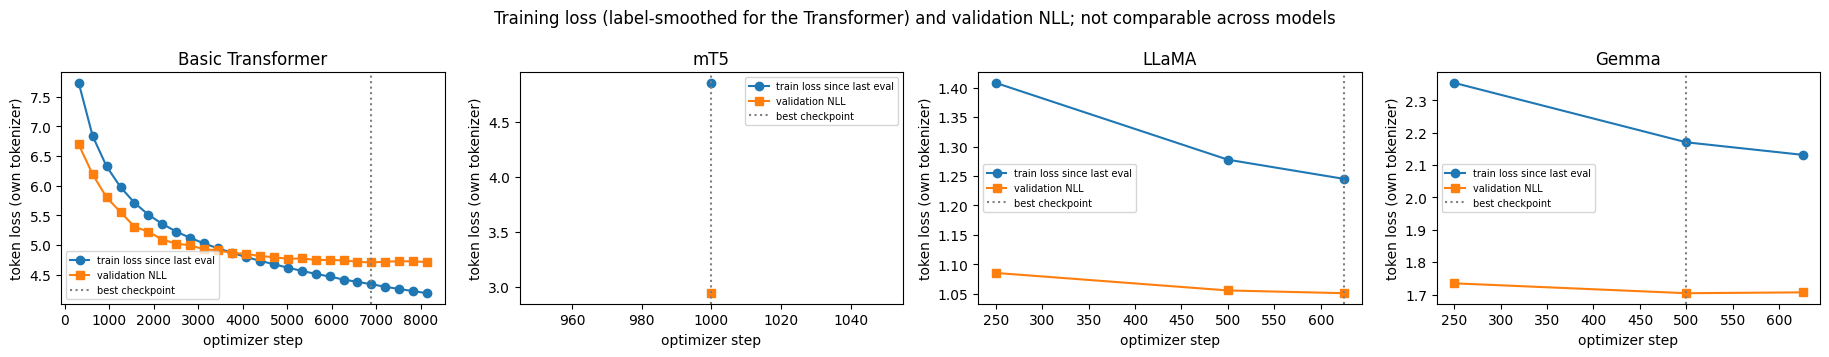

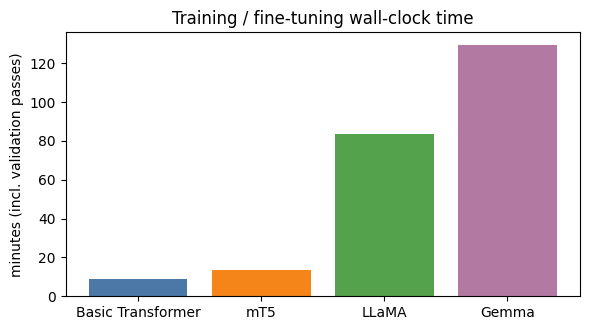

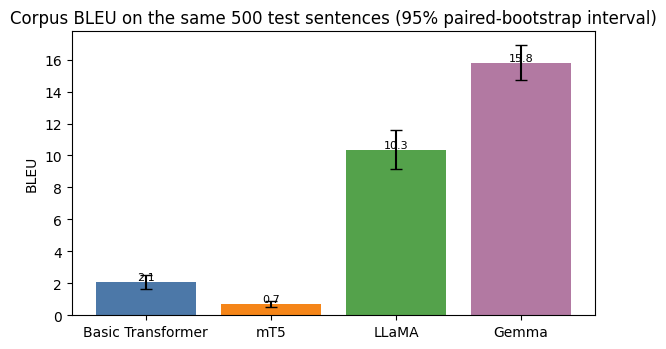

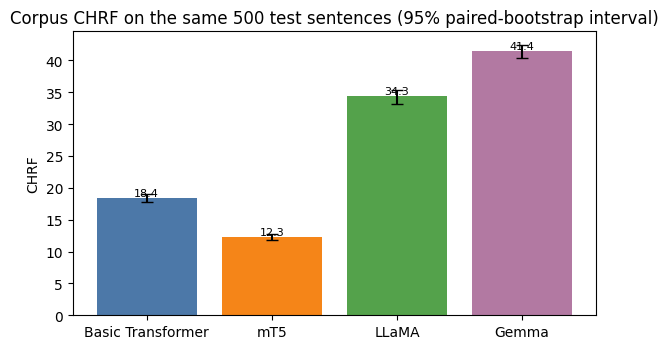

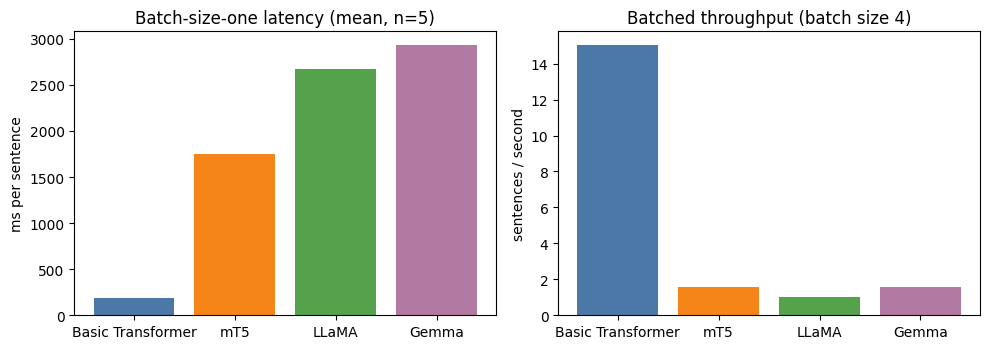

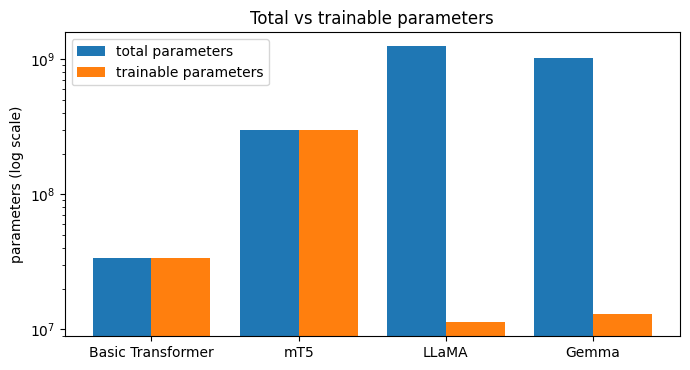

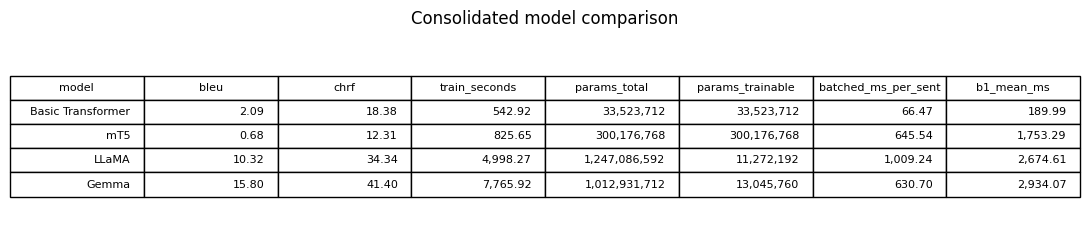

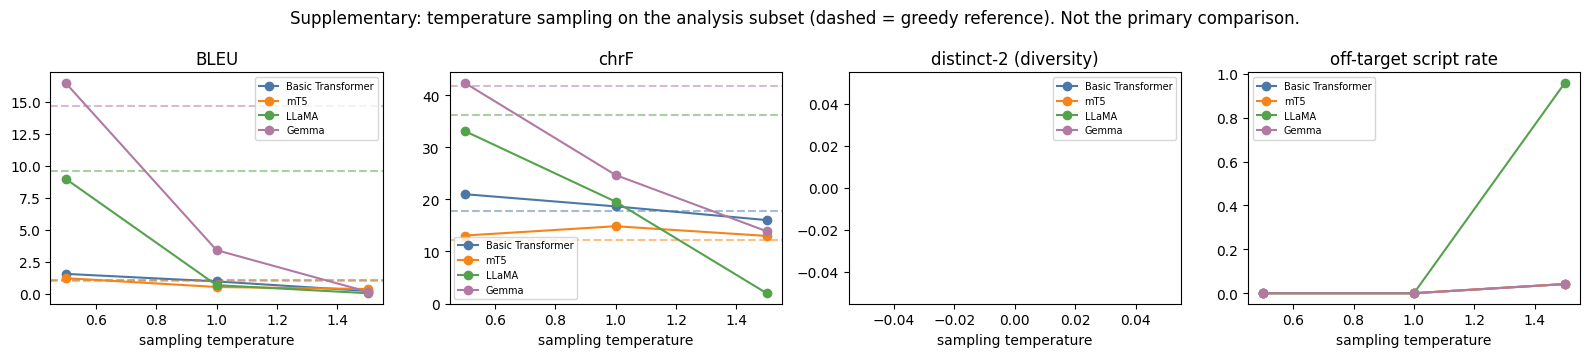

plots saved to /kaggle/working/assignment3_outputs/plots


In [44]:
# ===================== 15a. PLOTS =====================
colors = {"transformer": "#4C78A8", "mt5": "#F58518", "llama": "#54A24B", "gemma": "#B279A2"}
def savefig(name): plt.tight_layout(); plt.savefig(OUT / "plots" / name, dpi=150); plt.show()

trained = [m for m in OK if len(HIST) and m in set(HIST.model)]
if trained:                                                                   # 2. training / validation curves
    fig, axes = plt.subplots(1, len(trained), figsize=(4.6 * len(trained), 3.6), squeeze=False)
    for ax, m in zip(axes[0], trained):
        h = HIST[HIST.model == m]; x = h.step
        ax.plot(x, h.train_loss, "o-", label="train loss since last eval"); ax.plot(x, h.val_nll, "s-", label="validation NLL")
        bi = h[h.improved].tail(1); ax.axvline(int(bi.step.iloc[0]), ls=":", c="gray", label="best checkpoint") if len(bi) else None
        ax.set_title(f"{LABEL[m]}"); ax.set_xlabel("optimizer step"); ax.set_ylabel("token loss (own tokenizer)"); ax.legend(fontsize=7)
    plt.suptitle("Training loss (label-smoothed for the Transformer) and validation NLL; not comparable across models"); savefig("loss_curves.png")

fig, ax = plt.subplots(figsize=(6, 3.4))                                       # 3. training time
tt = [(LABEL[m], SUMMARY[m]["train"]["train_seconds"] / 60) for m in OK if SUMMARY[m].get("train")]
if tt:
    ax.bar([a for a, _ in tt], [b for _, b in tt], color=[colors[m] for m in OK if SUMMARY[m].get("train")]); ax.set_ylabel("minutes (incl. validation passes)")
for m in OK:
    if not SUMMARY[m].get("train"): ax.text(0.5, 0.9, f"{LABEL[m]}: no training (prompting only)", transform=ax.transAxes, ha="center", fontsize=8)
ax.set_title("Training / fine-tuning wall-clock time"); savefig("training_time.png")

for metric, fname in [("bleu", "bleu_comparison.png"), ("chrf", "chrf_comparison.png")]:   # 4, 5. BLEU and chrF with bootstrap intervals
    fig, ax = plt.subplots(figsize=(6, 3.6)); mi = METRICS.set_index("model").loc[OK]
    err = np.array([mi[metric] - mi[f"{metric}_ci_low"], mi[f"{metric}_ci_high"] - mi[metric]]).clip(min=0)
    ax.bar([LABEL[m] for m in OK], mi[metric], yerr=err, capsize=4, color=[colors[m] for m in OK]); ax.set_ylabel(metric.upper())
    ax.set_title(f"Corpus {metric.upper()} on the same {len(TEST_IDS)} test sentences (95% paired-bootstrap interval)"); [ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8) for i, v in enumerate(mi[metric])]; savefig(fname)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6)); ti = TIMING.set_index("model").loc[OK]       # 6. latency and throughput
axes[0].bar([LABEL[m] for m in OK], ti.b1_mean_ms, color=[colors[m] for m in OK]); axes[0].set_ylabel("ms per sentence"); axes[0].set_title(f"Batch-size-one latency (mean, n={int(ti.b1_n_timed.iloc[0])})")
axes[1].bar([LABEL[m] for m in OK], ti.batched_sent_per_s, color=[colors[m] for m in OK]); axes[1].set_ylabel("sentences / second"); axes[1].set_title(f"Batched throughput (batch size {int(ti.batch_size.iloc[0])})")
savefig("inference_latency_throughput.png")

fig, ax = plt.subplots(figsize=(7, 3.8)); pi = PARAMS.set_index("model").loc[OK]; x = np.arange(len(OK))   # 7. parameters
ax.bar(x - 0.2, pi.params_total, 0.4, label="total parameters"); ax.bar(x + 0.2, pi.params_trainable.clip(lower=1), 0.4, label="trainable parameters"); ax.set_yscale("log")
ax.set_xticks(x); ax.set_xticklabels([LABEL[m] for m in OK]); ax.set_ylabel("parameters (log scale)"); ax.legend(); ax.set_title("Total vs trainable parameters"); savefig("parameter_counts.png")

fig, ax = plt.subplots(figsize=(11, 0.6 + 0.5 * len(COMP))); ax.axis("off")                                  # 8. consolidated table as an image
show = COMP[["model", "bleu", "chrf", "train_seconds", "params_total", "params_trainable", "batched_ms_per_sent", "b1_mean_ms"]].copy()
cell = [[(f"{v:,.2f}" if isinstance(v, float) else (f"{v:,}" if isinstance(v, (int, np.integer)) else str(v))) for v in row] for row in show.values]
tb = ax.table(cellText=cell, colLabels=list(show.columns), loc="center"); tb.auto_set_font_size(False); tb.set_fontsize(8); tb.scale(1, 1.4); ax.set_title("Consolidated model comparison"); savefig("model_comparison_table.png")

if len(TEMP):                                                                  # 10. temperature plot
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
    for ax, (col, title) in zip(axes, [("bleu", "BLEU"), ("chrf", "chrF"), ("distinct2", "distinct-2 (diversity)"), ("off_target_rate", "off-target script rate")]):
        for m in OK:
            t = TEMP[(TEMP.model == m) & (TEMP.temperature != "greedy")]
            if t.empty: continue
            t = t.assign(T=t.temperature.astype(float)).sort_values("T"); ax.plot(t["T"], t[col], "o-", c=colors[m], label=LABEL[m])
            g = TEMP[(TEMP.model == m) & (TEMP.temperature == "greedy")]
            if col in ("bleu", "chrf") and len(g): ax.axhline(float(g[col].iloc[0]), ls="--", c=colors[m], alpha=.5)
        ax.set_xlabel("sampling temperature"); ax.set_title(title); ax.legend(fontsize=7)
    plt.suptitle("Supplementary: temperature sampling on the analysis subset (dashed = greedy reference). Not the primary comparison."); savefig("temperature_analysis.png")
print("plots saved to", OUT / "plots")

## 16. Export: manifest, RESULTS.md and downloadable ZIP
The final cell writes `manifest.json` (files created, models evaluated, skipped or failed with reasons, configuration), a `RESULTS.md` containing the actual numbers of this run (use it to fill the README results section), and a ZIP of all outputs **excluding** checkpoints, model caches and raw data. No token or secret is ever written.

In [45]:
# ===================== 16a. MANIFEST, RESULTS.md, ZIP =====================
status_final = {}
for m in MODELS:
    if m in OK: status_final[m] = {"status": "evaluated", "adaptation": SUMMARY[m]["adaptation"], **({k: v for k, v in STATUS.get(m, {}).items() if k not in ("status", "adaptation")})}
    elif m in STATUS: status_final[m] = STATUS[m]
    elif (OUT / "logs" / f"error_{m}.txt").exists(): status_final[m] = {"status": "failed", "reason": (OUT / "logs" / f"error_{m}.txt").read_text(encoding="utf-8")[-400:]}
    else: status_final[m] = {"status": "not run", "reason": "no results found in this output folder (disabled in RUN_MODELS or not executed)"}

EXCLUDE_DIRS = {"checkpoints"}
def exportable(p: Path) -> bool:
    return p.is_file() and not (set(p.relative_to(OUT).parts[:-1]) & EXCLUDE_DIRS) and p.suffix not in {".pt", ".safetensors", ".bin"} and p.name != "spm_train.txt"
files = [{"path": str(p.relative_to(OUT)), "mb": round(p.stat().st_size / 1e6, 3), "sha256": sha256_file(p) if p.stat().st_size < 60e6 else None} for p in sorted(OUT.rglob("*")) if exportable(p)]
ckpts = [{"path": str(p.relative_to(OUT)), "mb": dir_size_mb(p), "in_zip": False} for p in sorted((OUT / "checkpoints").glob("*/*"))] if (OUT / "checkpoints").exists() else []
manifest = {"profile": PROFILE, "dataset": DATASET_INFO["name"], "dataset_url": DATASET_INFO["url"], "dataset_license": DATASET_INFO["license"], "actual_split_sizes": ACTUAL_SPLITS,
            "model_ids": MODEL_IDS, "models_evaluated": OK, "models_skipped_or_failed": {m: s for m, s in status_final.items() if s["status"] != "evaluated"}, "model_status": status_final,
            "primary_decoding": "greedy (num_beams=1); temperature sampling is supplementary", "metric_config": METRIC_CONFIG, "best_model_statement": BEST_STATEMENT,
            "human_evaluation": "not completed (rubric template provided)", "environment": ENV, "files": files, "checkpoints_not_in_zip": ckpts,
            "note": "No secrets or raw dataset copies are stored. Scores come from the files listed here."}
save_json(manifest, OUT / "manifest.json")

res = ["# Results of this run (generated by the notebook)", "",
       f"Profile `{PROFILE}`; dataset: {DATASET_INFO['name']} ({DATASET_INFO['url']}); licence: {DATASET_INFO['license']}", "",
       f"Actual examples used: {ACTUAL_SPLITS}. Test sentences are identical for all systems. Primary decoding: greedy.", "",
       "## Model comparison", "", md_table(COMP, ["model", "adaptation", "bleu", "chrf", "train_seconds", "params_total", "params_trainable", "batched_ms_per_sent", "b1_mean_ms", "sent_per_s"], maxw=60, floatfmt="{:,.2f}"), "",
       "## Conclusion (rule-based, from the recorded evidence)", "", BEST_STATEMENT, "",
       "## Status of every model", "", *[f"- **{LABEL[m]}**: {s['status']}" + (f" ({s.get('reason')})" if s.get("reason") else "") + (f", fallback: {s['fallback']}" if s.get("fallback") else "") for m, s in status_final.items()], "",
       "## Metric configuration", "", "```json", json.dumps(METRIC_CONFIG, indent=1), "```", "",
       "## Notes", "", "- BLEU and chrF come from one sacreBLEU implementation on the same references. Parameter counts list total and trainable separately.",
       "- Systems differ in pretraining, size, tokenizer and adaptation (scratch training vs full fine-tuning vs LoRA), so the comparison ranks these systems, not architectures in isolation.",
       "- Qualitative analysis is an example-based inspection; no human ratings are included unless you add them."]
(OUT / "RESULTS.md").write_text("\n".join(res), encoding="utf-8")
ZIP = (Path("/kaggle/working") if Path("/kaggle/working").exists() else OUT.parent) / "assignment3_outputs.zip"
if ZIP.exists(): ZIP.unlink()
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob("*")):
        if exportable(p): z.write(p, Path("assignment3_outputs") / p.relative_to(OUT))
print(f"manifest: {OUT/'manifest.json'}\nresults : {OUT/'RESULTS.md'}\nzip     : {ZIP} ({ZIP.stat().st_size/1e6:.1f} MB, checkpoints excluded)")
print("\nmodel status:", json.dumps({m: s['status'] for m, s in status_final.items()}))
print("\nconclusion:", BEST_STATEMENT)

manifest: /kaggle/working/assignment3_outputs/manifest.json
results : /kaggle/working/assignment3_outputs/RESULTS.md
zip     : /kaggle/working/assignment3_outputs.zip (1.1 MB, checkpoints excluded)

model status: {"transformer": "evaluated", "mt5": "evaluated", "llama": "evaluated", "gemma": "evaluated"}

conclusion: Gemma has the highest BLEU (15.80) and chrF (41.40). Its lead over the runner-up LLaMA is statistically significant after Holm correction (paired bootstrap, 300 resamples) on both metrics. Lowest batched latency: Basic Transformer. Systems differ in pretraining, size, tokenizer and adaptation, so this ranks these four systems, not the architectures in isolation.


## 17. Limitations and honest reporting
* Results are valid only for the profile, subsets, seeds and hardware recorded in `config/` and `manifest.json`. A model fine-tuned from pretrained weights is not equivalent to a Transformer trained from scratch on the same small subset; pretraining data, model size, tokenizer and adaptation method (full fine-tuning, LoRA, prompting) all differ and are reported rather than hidden.
* The pretrained models may have seen WMT-style newswire text during pretraining; this cannot be checked here.
* The test set is newswire while most training data is not, so absolute scores can be low, especially for the model trained from scratch on a small subset.
* GPU runs are not bit-for-bit deterministic. Sampling is reproducible only when seeds, batch composition and software versions match.
* The qualitative section is an example-based inspection with automatic flags; no human ratings are included unless you fill in the blinded rubric template.
* If any model is marked failed or skipped in the status table, no score was invented for it.